# Pós-Graduação em IA Aplicada
### Unidade Curricular: Machine Learning
**Professor:** Giancarlo Marchesini, Me.

---

# Comparando o Pipeline Completo de Classificação com o Scikit-learn

Este material usa **um único dataset**, do início ao fim, para comparar de forma direta:

- diferentes **scalers** (formas de padronizar os dados);
- diferentes **estratégias de divisão** dos dados (split único x validação cruzada);
- diferentes **classificadores** disponíveis no scikit-learn (como usar cada um);
- diferentes **métricas** de avaliação.

**Formato:** duas aulas de 3h, no mesmo notebook. O marcador ⏸️ **Fim da Aula 1** indica onde parar.

- **Aula 1:** os dados, o pipeline básico, scalers, estratégias de divisão e validação (incluindo `StratifiedKFold`), os classificadores do scikit-learn e o ajuste de hiperparâmetros.
- **Aula 2:** as métricas de avaliação, como salvar e reutilizar o modelo, e os exercícios finais.

> ▶️ **Como usar no Google Colab:** `Arquivo > Fazer upload de notebook`, envie este `.ipynb` e execute as células **em ordem** (`Ambiente de execução > Executar tudo` também funciona).

## Objetivos

Ao final das duas aulas, vocês devem ser capazes de:

1. Montar um pipeline de classificação completo — dos dados brutos às métricas — usando `Pipeline` do scikit-learn.
2. Explicar o que cada `Scaler` faz e medir seu efeito real no desempenho.
3. Comparar as estratégias de divisão dos dados — treino/teste, treino/validação/teste e validação cruzada com `StratifiedKFold` — entendendo quando usar cada uma e por que o `Pipeline` é indispensável dentro da validação cruzada.
4. Instanciar e treinar os principais classificadores do scikit-learn, sabendo a ideia central de cada um.
5. Ajustar os hiperparâmetros de cada classificador com Grid Search e Random Search, entendendo quando usar cada técnica.
6. Escolher a métrica certa para o problema, e não usar acurácia por hábito.

## O dataset: Wine

O **Wine dataset** é um clássico do scikit-learn: 178 amostras de vinhos italianos, cada uma com 13 medidas químicas (teor alcoólico, acidez, magnésio, fenóis, cor, entre outras), classificadas em 3 cultivares de uva.

| Característica | Valor |
|---|---|
| Amostras | 178 |
| Variáveis | 13, todas numéricas |
| Classes | 3 cultivares: `class_0` (59), `class_1` (71), `class_2` (48) |
| Valores faltantes | Nenhum |
| Fonte | UCI Machine Learning Repository, embutido no scikit-learn |

É um dataset **pequeno, limpo e razoavelmente balanceado** — ideal para isolar o efeito de cada decisão do pipeline, sem o ruído de faltantes ou desbalanceamento severo.

In [5]:
# Bibliotecas usadas ao longo das duas aulas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.model_selection import (
    train_test_split, KFold, StratifiedKFold, cross_val_score, cross_validate, GridSearchCV, RandomizedSearchCV,
)
from scipy.stats import loguniform, randint
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
)

SEMENTE = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

print("Bibliotecas prontas.")

Bibliotecas prontas.


# Módulo 1 — Conhecendo os dados

> 🎯 **Objetivo:** carregar o dataset e entender sua estrutura antes de qualquer modelagem.

In [6]:
dados = load_wine()

# Monta um DataFrame único, com nomes de coluna legíveis e a classe já traduzida
df = pd.DataFrame(dados.data, columns=dados.feature_names)
df["classe"] = dados.target
nomes_classes = [str(nome) for nome in dados.target_names]

print(f"Formato: {df.shape[0]} amostras, {df.shape[1] - 1} variáveis, {df['classe'].nunique()} classes")
df.head()

Formato: 178 amostras, 13 variáveis, 3 classes


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,classe
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


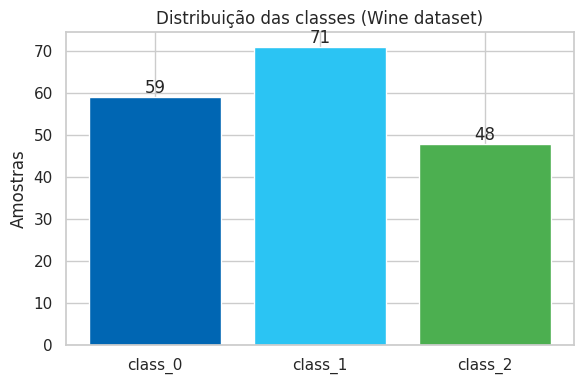

In [7]:
# Distribuição das classes: o dataset é balanceado o suficiente para não exigir tratamento especial
contagem = df["classe"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(nomes_classes, contagem.values, color=["#0066B3", "#2BC4F3", "#4CAF50"])
for posicao, valor in enumerate(contagem.values):
    plt.text(posicao, valor, str(valor), ha="center", va="bottom")
plt.title("Distribuição das classes (Wine dataset)")
plt.ylabel("Amostras")
plt.tight_layout()
plt.show()

In [8]:
# Estatísticas descritivas: reparem nas escalas MUITO diferentes entre colunas
df.drop(columns="classe").describe().T[["mean", "std", "min", "max"]].round(1)

,mean,std,min,max
alcohol,13.0,0.8,11.0,14.8
malic_acid,2.3,1.1,0.7,5.8
ash,2.4,0.3,1.4,3.2
alcalinity_of_ash,19.5,3.3,10.6,30.0
magnesium,99.7,14.3,70.0,162.0
total_phenols,2.3,0.6,1.0,3.9
flavanoids,2.0,1.0,0.3,5.1
nonflavanoid_phenols,0.4,0.1,0.1,0.7
proanthocyanins,1.6,0.6,0.4,3.6
color_intensity,5.1,2.3,1.3,13.0


> 📌 **Reparem na tabela acima.** `magnesium` varia de 70 a 162, enquanto `total_phenols` varia de 1,0 a 3,9. Essa diferença de escala é o motivo do Módulo 3, sobre scalers.

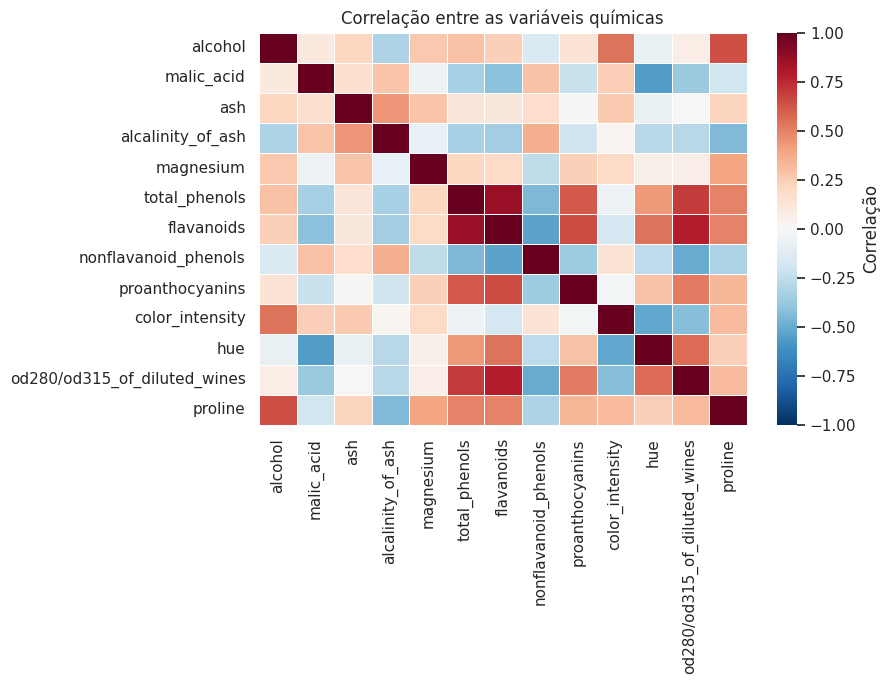

In [9]:
# Correlação entre as variáveis: ajuda a antecipar quais colunas carregam informação parecida
plt.figure(figsize=(9, 7))
sns.heatmap(df.drop(columns="classe").corr(), cmap="RdBu_r", vmin=-1, vmax=1,
            linewidths=0.4, cbar_kws={"label": "Correlação"})
plt.title("Correlação entre as variáveis químicas")
plt.tight_layout()
plt.show()

# Módulo 2 — O primeiro pipeline: dados até a métrica

> 🎯 **Objetivo:** construir o fluxo completo — split, padronização, modelo, previsão, métrica — em sua forma mais simples, para servir de referência ao restante da aula.

## 2.1 Dividindo em treino e teste

`stratify=y` garante que treino e teste mantenham a mesma proporção das 3 classes.

In [10]:
X = df.drop(columns="classe")
y = df["classe"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEMENTE
)

print(f"Treino: {len(X_treino)} amostras | Teste: {len(X_teste)} amostras")
print("Proporção de classes no treino:", y_treino.value_counts(normalize=True).sort_index().round(2).tolist())
print("Proporção de classes no teste: ", y_teste.value_counts(normalize=True).sort_index().round(2).tolist())

Treino: 124 amostras | Teste: 54 amostras
Proporção de classes no treino: [0.33, 0.4, 0.27]
Proporção de classes no teste:  [0.33, 0.39, 0.28]


## 2.2 Por que padronizar os dados?

Muitos classificadores (regressão logística, k-NN, SVM, redes neurais) calculam distâncias ou somas ponderadas entre variáveis. Se uma coluna varia de 70 a 162 e outra de 1 a 4, a primeira **domina** o cálculo — não porque seja mais importante, mas porque está em uma escala maior.

Vamos ver isso na prática com o k-NN, que decide pela distância entre pontos.

In [11]:
from sklearn.neighbors import KNeighborsClassifier

# k-NN SEM padronização
modelo_sem_escala = KNeighborsClassifier(n_neighbors=5)
modelo_sem_escala.fit(X_treino, y_treino)
acuracia_sem_escala = accuracy_score(y_teste, modelo_sem_escala.predict(X_teste))

# k-NN COM padronização, usando um Pipeline
modelo_com_escala = Pipeline([
    ("escalonador", StandardScaler()),
    ("modelo", KNeighborsClassifier(n_neighbors=5)),
])
modelo_com_escala.fit(X_treino, y_treino)
acuracia_com_escala = accuracy_score(y_teste, modelo_com_escala.predict(X_teste))

print(f"k-NN SEM padronização: {acuracia_sem_escala:.1%} de acurácia")
print(f"k-NN COM padronização: {acuracia_com_escala:.1%} de acurácia")

k-NN SEM padronização: 72.2% de acurácia
k-NN COM padronização: 94.4% de acurácia


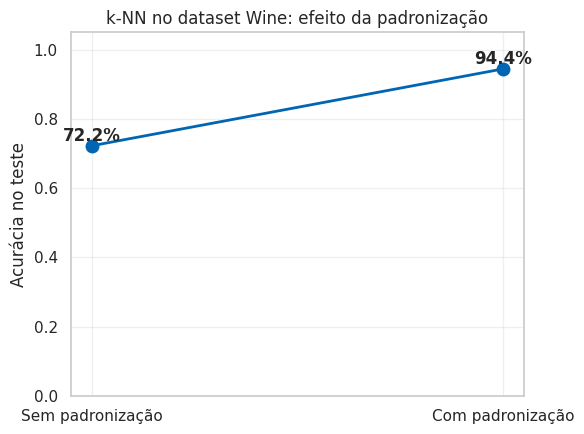

In [12]:
# Gráfico de linha: um ponto para cada situação, ligados para destacar o salto de desempenho
plt.figure(figsize=(6, 4.5))
situacoes = ["Sem padronização", "Com padronização"]
acuracias = [acuracia_sem_escala, acuracia_com_escala]

plt.plot(situacoes, acuracias, marker="o", markersize=9, linewidth=2, color="#0066B3")
for x, y_valor in zip(situacoes, acuracias):
    plt.text(x, y_valor + 0.015, f"{y_valor:.1%}", ha="center", fontweight="bold")

plt.ylabel("Acurácia no teste")
plt.title("k-NN no dataset Wine: efeito da padronização")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

> 📌 **A diferença é grande, e não é coincidência.** É exatamente esse tipo de efeito que o Módulo 3 vai medir de forma sistemática, com vários scalers e vários classificadores.

## 2.3 O padrão do `Pipeline`

Todo classificador do scikit-learn segue a mesma interface: `fit(X, y)` para treinar, `predict(X)` para prever a classe, e `predict_proba(X)` para prever probabilidades (quando disponível). O `Pipeline` encadeia pré-processamento e modelo como se fossem um único objeto — o que evita **vazamento de dados**: o scaler é ajustado apenas com o treino, nunca com o teste.

Esse é o padrão que usaremos em todas as comparações a seguir:

```python
pipeline = Pipeline([
    ("escalonador", StandardScaler()),
    ("modelo", NomeDoClassificador(...)),
])
pipeline.fit(X_treino, y_treino)
previsoes = pipeline.predict(X_teste)
```

# Módulo 3 — Comparando os Scalers

> 🎯 **Objetivo:** medir o efeito de cada scaler, em vez de escolher um por hábito.

| Scaler | O que faz |
|---|---|
| `StandardScaler` | Transforma cada coluna para média 0 e desvio-padrão 1 |
| `MinMaxScaler` | Comprime cada coluna para o intervalo [0, 1] |
| `RobustScaler` | Usa mediana e intervalo interquartil — mais resistente a outliers |
| Nenhum | Mantém os dados na escala original |

Vamos testar as quatro opções com **dois classificadores de naturezas diferentes**: k-NN (decide por distância — deve ser sensível à escala) e Árvore de Decisão (decide por cortes — deve ser indiferente à escala). Usar dois classificadores em vez de um evita a conclusão errada de que "scaler sempre importa" ou "scaler nunca importa".

In [13]:
from sklearn.tree import DecisionTreeClassifier

scalers = {
    "Sem scaler": None,
    "StandardScaler": StandardScaler(),
    "MinMaxScaler": MinMaxScaler(),
    "RobustScaler": RobustScaler(),
}

classificadores_teste = {
    "k-NN (distância)": KNeighborsClassifier(n_neighbors=5),
    "Árvore de Decisão (cortes)": DecisionTreeClassifier(random_state=SEMENTE),
}

validacao_cruzada = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

resultados_scaler = []
for nome_scaler, scaler in scalers.items():
    for nome_modelo, modelo in classificadores_teste.items():
        etapas = [("modelo", modelo)] if scaler is None else [("escalonador", scaler), ("modelo", modelo)]
        pipeline = Pipeline(etapas)
        notas = cross_val_score(pipeline, X_treino, y_treino, cv=validacao_cruzada, scoring="accuracy")
        resultados_scaler.append({"scaler": nome_scaler, "modelo": nome_modelo, "acuracia": notas.mean()})

tabela_scaler = pd.DataFrame(resultados_scaler).pivot(index="scaler", columns="modelo", values="acuracia")
# Reordena as linhas na sequência lógica (o pivot devolve em ordem alfabética por padrão)
tabela_scaler = tabela_scaler.reindex(["Sem scaler", "StandardScaler", "MinMaxScaler", "RobustScaler"])
tabela_scaler.round(3)

modelo,k-NN (distância),Árvore de Decisão (cortes)
scaler,,
Sem scaler,0.718,0.878
StandardScaler,0.968,0.878
MinMaxScaler,0.960,0.878
RobustScaler,0.944,0.878


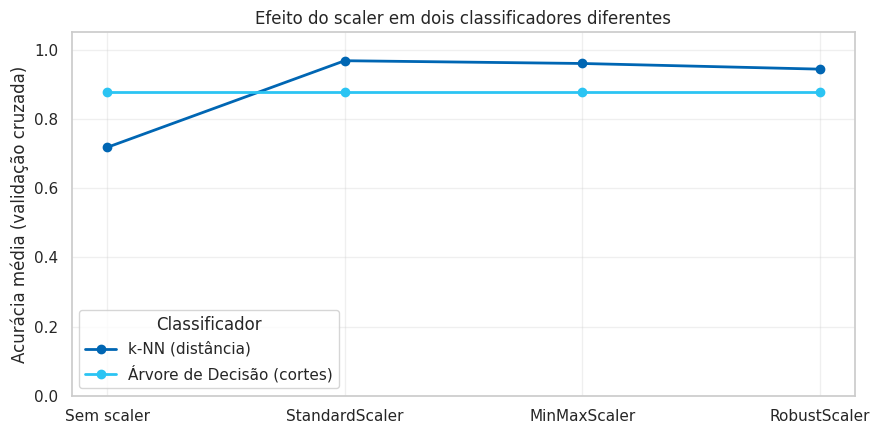

In [14]:
# Gráfico de linha: um ponto por scaler, uma linha por classificador.
# Isso deixa a TENDÊNCIA visível - se o desempenho sobe, desce ou fica estável entre os scalers -
# de um jeito que barras isoladas, lado a lado, não mostram tão bem.
plt.figure(figsize=(9, 4.5))
cores = {"k-NN (distância)": "#0066B3", "Árvore de Decisão (cortes)": "#2BC4F3"}
for nome_modelo in tabela_scaler.columns:
    plt.plot(tabela_scaler.index, tabela_scaler[nome_modelo], marker="o", linewidth=2,
             label=nome_modelo, color=cores.get(nome_modelo))
plt.ylabel("Acurácia média (validação cruzada)")
plt.title("Efeito do scaler em dois classificadores diferentes")
plt.ylim(0, 1.05)
plt.legend(title="Classificador")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

> 📌 **Leitura:** a Árvore de Decisão praticamente não muda entre os quatro scalers — ela compara cada coluna consigo mesma, então a escala é irrelevante. O k-NN, por outro lado, varia bastante: sem padronização, colunas em escala maior (como `magnesium`) dominam o cálculo de distância.
>
> **Conclusão prática:** padronizar nunca prejudica e é essencial para modelos baseados em distância ou em soma ponderada (k-NN, SVM, regressão logística, redes neurais). Para árvores e ensembles de árvores, é indiferente — mas manter o scaler no pipeline não custa nada e evita ter que reescrever o código se você trocar de classificador depois.

# Módulo 4 — Estratégias de Divisão e Validação dos Dados

> 🎯 **Objetivo:** entender, com calma, as diferentes formas de dividir os dados — treino/teste, treino/validação/teste e validação cruzada — e por que a validação cruzada quase sempre usa `StratifiedKFold` em classificação. No final, unimos tudo isso ao `Pipeline`.

## 4.1 Relembrando o split simples: treino e teste

No Módulo 2 dividimos os dados uma única vez: 70% para treino, 30% para teste, com `stratify=y`. É a forma mais simples de avaliar um modelo — treinamos em uma parte e medimos o desempenho na outra, que o modelo nunca viu.

```python
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEMENTE)
```

Isso funciona bem **quando só há uma decisão a tomar**: treinar um modelo e medir seu desempenho. O problema aparece quando há **várias** decisões — qual scaler, qual classificador, quais hiperparâmetros — como vimos nos Módulos 3, 5 e 6.

## 4.2 Um problema sutil: decidir usando o conjunto de teste

Imagine que, para escolher o melhor scaler no Módulo 3, tivéssemos testado cada opção diretamente no `X_teste` e escolhido a que desse a maior acurácia ali. O número final que reportássemos não seria mais uma avaliação **independente** — ele teria sido "contaminado" pela nossa própria escolha, feita com base nesse mesmo conjunto. É como estudar para uma prova usando as respostas da própria prova: a nota vai parecer ótima, mas não mede o que você realmente sabe.

Quanto mais decisões você toma **olhando para o teste**, mais otimista (e menos confiável) o resultado final se torna. A solução clássica é nunca deixar que o teste participe de nenhuma decisão — só da avaliação final, uma única vez.

## 4.3 A solução clássica: treino, validação e teste

Uma forma de resolver isso é dividir os dados em **três** partes, não duas:

| Conjunto | Papel |
|---|---|
| **Treino** | Onde o modelo efetivamente aprende (`.fit()`) |
| **Validação** | Onde comparamos scalers, classificadores e hiperparâmetros — decisões são tomadas aqui |
| **Teste** | Tocado **uma única vez**, no final, depois que todas as decisões já foram tomadas |

In [15]:
# Primeiro split: separamos o teste (20%), que não será mais tocado até a avaliação final
X_treino_val, X_teste_3vias, y_treino_val, y_teste_3vias = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMENTE)

# Segundo split: dividimos o restante em treino (60% do total) e validação (20% do total)
X_treino_3vias, X_validacao_3vias, y_treino_3vias, y_validacao_3vias = train_test_split(
    X_treino_val, y_treino_val, test_size=0.25, stratify=y_treino_val, random_state=SEMENTE)
# 0.25 dos 80% restantes = 20% do total original

print(f"Treino:    {len(X_treino_3vias)} amostras ({len(X_treino_3vias)/len(X):.0%})")
print(f"Validação: {len(X_validacao_3vias)} amostras ({len(X_validacao_3vias)/len(X):.0%})")
print(f"Teste:     {len(X_teste_3vias)} amostras ({len(X_teste_3vias)/len(X):.0%})")

Treino:    106 amostras (60%)
Validação: 36 amostras (20%)
Teste:     36 amostras (20%)


> 📌 **O fluxo de trabalho correto com três conjuntos:** treine no conjunto de treino, compare quantas configurações quiser usando o conjunto de validação, escolha a vencedora, e só então meça o desempenho final no conjunto de teste — **uma única vez**. Se o resultado no teste for ruim, a resposta **não** é voltar e tentar outra configuração só para "ver se melhora" — isso reintroduziria exatamente o problema da Seção 4.2, pela porta dos fundos.

**A limitação desse método:** a fatia de validação é **fixa** e **usada só para comparar**, nunca para treinar o modelo final — em um dataset pequeno como o nosso (178 amostras), reservar 20% apenas para validação é desperdiçar dados que poderiam ajudar o modelo a aprender melhor. E como vamos ver a seguir, essa fatia fixa tem o mesmo problema que qualquer split único: o resultado depende de **qual fatia, por sorte, calhou de ser a validação**.

## 4.4 O quanto um único split pode variar

Vamos repetir o mesmo split treino/teste 10 vezes, cada vez com uma semente diferente, e ver o quanto a acurácia varia — mesmo sendo **sempre o mesmo modelo, sempre os mesmos dados**. O mesmo problema valeria para a fatia de validação da Seção 4.3.

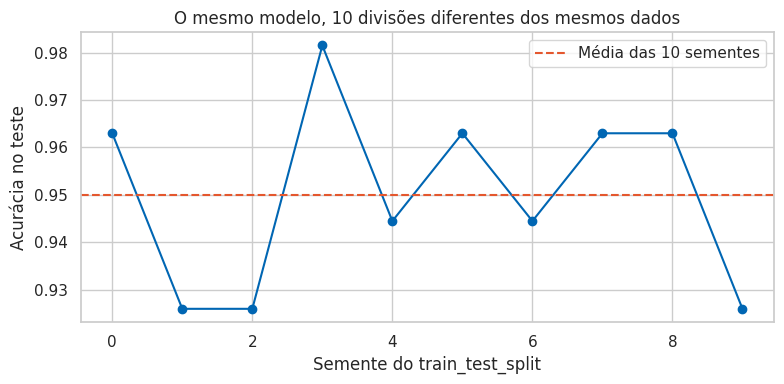

Acurácia mínima: 92.6% | máxima: 98.1% | diferença: 5.6%


In [16]:
pipeline_referencia = Pipeline([
    ("escalonador", StandardScaler()),
    ("modelo", KNeighborsClassifier(n_neighbors=5)),
])

acuracias_por_semente = []
for semente in range(10):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.30, stratify=y, random_state=semente)
    pipeline_referencia.fit(Xa, ya)
    acuracias_por_semente.append(accuracy_score(yb, pipeline_referencia.predict(Xb)))

plt.figure(figsize=(8, 4))
plt.plot(range(10), acuracias_por_semente, marker="o", color="#0066B3")
plt.axhline(np.mean(acuracias_por_semente), color="#E4572E", linestyle="--", label="Média das 10 sementes")
plt.xlabel("Semente do train_test_split")
plt.ylabel("Acurácia no teste")
plt.title("O mesmo modelo, 10 divisões diferentes dos mesmos dados")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Acurácia mínima: {min(acuracias_por_semente):.1%} | máxima: {max(acuracias_por_semente):.1%} | "
      f"diferença: {max(acuracias_por_semente) - min(acuracias_por_semente):.1%}")

> 📌 **Nada mudou no modelo ou nos dados — só a divisão.** E ainda assim a acurácia varia vários pontos percentuais. Se você rodasse um único split (de teste, **ou** de validação) e reportasse "meu modelo tem X% de acurácia", esse número poderia ter saído de qualquer ponto desse gráfico. Precisamos de algo mais estável que uma única fatia de sorte.

## 4.5 Validação cruzada (K-Fold): usando todos os dados, tanto para treinar quanto para validar

A ideia da validação cruzada é simples e elegante: em vez de reservar **uma** fatia fixa de validação, dividimos os dados em $k$ partes iguais (**dobras**, ou *folds*) e repetimos o treino $k$ vezes. Em cada repetição, **uma dobra diferente** vira a validação, e as outras $k-1$ formam o treino:

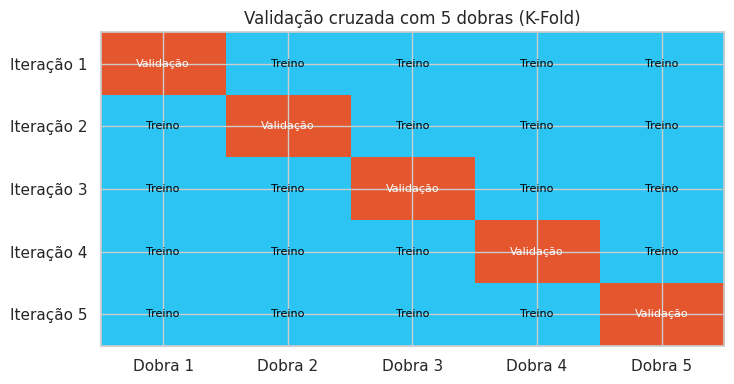

In [17]:
from matplotlib.colors import ListedColormap

NUMERO_DOBRAS = 5
matriz_ilustrativa = np.zeros((NUMERO_DOBRAS, NUMERO_DOBRAS))
for i in range(NUMERO_DOBRAS):
    matriz_ilustrativa[i, i] = 1  # 1 marca a dobra usada como validação NAQUELA iteração

figura, eixo = plt.subplots(figsize=(7.5, 4))
eixo.imshow(matriz_ilustrativa, cmap=ListedColormap(["#2BC4F3", "#E4572E"]), aspect="auto")
for i in range(NUMERO_DOBRAS):
    for j in range(NUMERO_DOBRAS):
        rotulo = "Validação" if matriz_ilustrativa[i, j] == 1 else "Treino"
        eixo.text(j, i, rotulo, ha="center", va="center", fontsize=8,
                  color="white" if matriz_ilustrativa[i, j] == 1 else "black")
eixo.set_xticks(range(NUMERO_DOBRAS), [f"Dobra {k+1}" for k in range(NUMERO_DOBRAS)])
eixo.set_yticks(range(NUMERO_DOBRAS), [f"Iteração {k+1}" for k in range(NUMERO_DOBRAS)])
eixo.set_title("Validação cruzada com 5 dobras (K-Fold)")
plt.tight_layout()
plt.show()

Repare que **cada dobra** vira validação exatamente uma vez, e faz parte do treino nas outras quatro iterações — ou seja, **todas as 178 amostras** acabam sendo usadas tanto para treinar quanto para validar, só nunca ao mesmo tempo. Ao final, calculamos a métrica em cada uma das $k$ iterações e tiramos a **média** (e o desvio-padrão, que mede a estabilidade do resultado).

No scikit-learn, isso é feito com `cross_val_score`, passando um objeto que define como as dobras são criadas — no nosso caso, `validacao_cruzada = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)`, já definido no Módulo 3 (a razão do "Stratified" vem na Seção 4.6).

In [18]:
notas_cv = cross_val_score(pipeline_referencia, X, y, cv=validacao_cruzada, scoring="accuracy")

print(f"Acurácia em cada uma das 5 dobras: {np.round(notas_cv, 3)}")
print(f"Média: {notas_cv.mean():.1%}  |  Desvio-padrão: {notas_cv.std():.1%}")

comparacao_split = pd.DataFrame({
    "Split único (10 sementes)": [np.mean(acuracias_por_semente), np.std(acuracias_por_semente),
                                  max(acuracias_por_semente) - min(acuracias_por_semente)],
    "Validação cruzada (5 dobras)": [notas_cv.mean(), notas_cv.std(), notas_cv.max() - notas_cv.min()],
}, index=["Acurácia média", "Desvio-padrão", "Amplitude (máx - mín)"])
comparacao_split.round(4)

Acurácia em cada uma das 5 dobras: [0.972 0.972 1.    0.943 0.971]
Média: 97.2%  |  Desvio-padrão: 1.8%


,Split único (10 sementes),Validação cruzada (5 dobras)
Acurácia média,0.9500,0.9717
Desvio-padrão,0.0186,0.0181
Amplitude (máx - mín),0.0556,0.0571


> 📌 **A média é parecida; o que muda é a informação sobre a incerteza.** A validação cruzada usa **todas** as amostras para validar (uma vez cada), enquanto um split único usa só uma fração, e o resultado depende de qual fração calhou de cair no teste ou na validação.
>
> **Regra prática:** para **comparar** classificadores, scalers ou hiperparâmetros, use validação cruzada — ela é mais estável, e é exatamente o que fizemos nos Módulos 3, 5 e 6. Reserve um split único (o conjunto de **teste**) para a avaliação final, feita uma única vez, depois que todas as escolhas já foram tomadas.

## 4.6 Por que "Stratified"? K-Fold comum pode gerar dobras desastrosas

Até aqui usamos `StratifiedKFold` sem explicar o "Stratified". Vamos ver o que aconteceria com o `KFold` comum — e, para isso, precisamos de um detalhe real do nosso dataset: o `load_wine` entrega os dados **ordenados por classe** (primeiro todas as amostras de `class_0`, depois `class_1`, depois `class_2`). Esse tipo de ordenação não é rara em dados reais — é comum quando os dados chegam agrupados por data, por lote de coleta ou por origem.

In [19]:
divisores = {"KFold comum (sem estratificar)": KFold(n_splits=5, shuffle=False),
            "StratifiedKFold": StratifiedKFold(n_splits=5, shuffle=False)}

for nome_divisor, divisor in divisores.items():
    print(f"\n{nome_divisor}:")
    for numero_dobra, (_, indices_validacao) in enumerate(divisor.split(X, y), start=1):
        contagem = y.iloc[indices_validacao].value_counts().reindex([0, 1, 2], fill_value=0)
        contagem_legivel = dict(zip([str(n) for n in nomes_classes], [int(v) for v in contagem.values]))
        print(f"  Dobra {numero_dobra} (validação): {contagem_legivel}")


KFold comum (sem estratificar):
  Dobra 1 (validação): {'class_0': 36, 'class_1': 0, 'class_2': 0}
  Dobra 2 (validação): {'class_0': 23, 'class_1': 13, 'class_2': 0}
  Dobra 3 (validação): {'class_0': 0, 'class_1': 36, 'class_2': 0}
  Dobra 4 (validação): {'class_0': 0, 'class_1': 22, 'class_2': 13}
  Dobra 5 (validação): {'class_0': 0, 'class_1': 0, 'class_2': 35}

StratifiedKFold:
  Dobra 1 (validação): {'class_0': 12, 'class_1': 14, 'class_2': 10}
  Dobra 2 (validação): {'class_0': 12, 'class_1': 14, 'class_2': 10}
  Dobra 3 (validação): {'class_0': 12, 'class_1': 14, 'class_2': 10}
  Dobra 4 (validação): {'class_0': 12, 'class_1': 14, 'class_2': 9}
  Dobra 5 (validação): {'class_0': 11, 'class_1': 15, 'class_2': 9}


> 🚩 **Olhem para o `KFold` comum.** Três das cinco dobras de validação ficam com **zero** amostras de duas das três classes — a Dobra 1 é inteiramente `class_0`, a Dobra 3 é inteiramente `class_1`. Um modelo avaliado nessa Dobra 1 seria testado **apenas** em `class_0`; a métrica dessa iteração não diz nada sobre como o modelo se comporta nas outras classes. A média final ficaria enviesada e a variação entre dobras, artificialmente enorme.
>
> O `StratifiedKFold` resolve isso preservando a **proporção original das classes em cada dobra** — todas as cinco ficam com uma mistura parecida com a da base inteira (por volta de 33% de cada classe, respeitando o pequeno desbalanceamento real). Por isso, em **classificação**, `StratifiedKFold` deve ser o padrão, e `KFold` comum só é seguro quando a ordem dos dados já é aleatória **e** as classes já são bem representadas em qualquer subconjunto — algo que, na prática, é difícil garantir de antemão. Por segurança, prefira sempre `StratifiedKFold`.

## 4.7 Unindo tudo: por que o `Pipeline` é indispensável dentro da validação cruzada

Voltando ao `Pipeline` do Módulo 2: ele não é só uma conveniência de código. Dentro da validação cruzada, ele é o que **impede o vazamento de dados entre as dobras**.

Lembre-se de como o `StandardScaler` funciona: ele calcula a média e o desvio-padrão dos dados que recebe, e usa esses números para padronizar. Se calculássemos essa média e esse desvio-padrão **uma única vez, com todos os dados**, antes de entrar na validação cruzada, cada dobra de treino "veria" informação estatística vinda também da dobra que deveria ser validação — um vazamento sutil, mas real.

O `Pipeline`, quando passado para `cross_val_score` (ou `cross_validate`, `GridSearchCV`, `RandomizedSearchCV`), resolve isso automaticamente: a cada dobra, ele **reajusta o scaler do zero**, usando **apenas** os dados de treino daquela dobra específica.

In [20]:
# ERRADO: ajusta o scaler UMA VEZ com todo o X_treino, antes da validação cruzada
scaler_global = StandardScaler().fit(X_treino)
X_treino_padronizado_global = scaler_global.transform(X_treino)
notas_com_vazamento = cross_val_score(KNeighborsClassifier(n_neighbors=5), X_treino_padronizado_global, y_treino,
                                      cv=validacao_cruzada, scoring="accuracy")

# CERTO: o Pipeline reajusta o scaler em CADA dobra, usando só os dados de treino daquela dobra
pipeline_sem_vazamento = Pipeline([("escalonador", StandardScaler()), ("modelo", KNeighborsClassifier(n_neighbors=5))])
notas_sem_vazamento = cross_val_score(pipeline_sem_vazamento, X_treino, y_treino,
                                      cv=validacao_cruzada, scoring="accuracy")

print(f"Scaler ajustado FORA do Pipeline (com vazamento): {notas_com_vazamento.mean():.4f}")
print(f"Scaler ajustado DENTRO do Pipeline (correto):      {notas_sem_vazamento.mean():.4f}")

# O resultado final pode até empatar - mas o MECANISMO do vazamento é real. Provamos isso
# comparando as estatísticas internas do scaler: a média usada em cada caso é diferente,
# porque foi calculada com um conjunto de amostras diferente.
indices_primeira_dobra_treino, _ = next(iter(validacao_cruzada.split(X_treino, y_treino)))
scaler_de_uma_dobra = StandardScaler().fit(X_treino.iloc[indices_primeira_dobra_treino])

print(f"\nMédia de 'alcohol' usada pelo scaler global (todo o X_treino): {scaler_global.mean_[0]:.4f}")
print(f"Média de 'alcohol' usada pelo scaler de UMA dobra de treino:    {scaler_de_uma_dobra.mean_[0]:.4f}")

Scaler ajustado FORA do Pipeline (com vazamento): 0.9680
Scaler ajustado DENTRO do Pipeline (correto):      0.9680

Média de 'alcohol' usada pelo scaler global (todo o X_treino): 12.9559
Média de 'alcohol' usada pelo scaler de UMA dobra de treino:    12.9574


> 📌 **Nesta execução, a acurácia final empatou** — o Wine é pequeno e bem-comportado, então a diferença entre as médias acima é pequena demais para mudar qual vizinho fica mais próximo no k-NN. Mas repare: as médias **são diferentes**. O vazamento **acontece** sempre que o scaler é ajustado fora do `Pipeline` — ele só nem sempre é grande o bastante para se refletir na métrica final. Em bases menores, mais desbalanceadas, ou com outliers mais extremos (lembrem do Módulo 3), esse mesmo mecanismo pode mudar o resultado de forma visível — e não há como saber de antemão se vai mudar ou não. Por isso a prática correta é sempre usar o `Pipeline`, mesmo quando "parece não fazer diferença".
>
> **A regra que resolve praticamente todo caso:** se uma etapa de pré-processamento **aprende alguma coisa dos dados** (média, desvio, categorias, componentes), ela pertence **dentro** do `Pipeline`. Só uma transformação fixa, que não depende do restante da base, pode ficar fora com segurança. É por isso que, desde o Módulo 2, nunca chamamos `scaler.fit()` fora de um `Pipeline` — exceto agora, de propósito, para mostrar o que aconteceria.

# Módulo 5 — Os Classificadores do Scikit-learn

> 🎯 **Objetivo:** para cada classificador, entender **como ele treina** (o que o `.fit()` calcula internamente) e **como ele infere** (o que o `.predict()` faz com um dado novo).

Para tornar a inferência concreta, vamos usar **o mesmo "vinho novo" em todos os classificadores**: pegamos a primeira amostra do nosso conjunto de teste e fingimos que acabou de chegar, sem rótulo. No final do módulo, revelamos a classe verdadeira e vemos quantos classificadores acertaram.

In [21]:
# "Vinho novo": uma amostra real do conjunto de teste, tratada como se o rótulo fosse desconhecido.
# Pipeline.predict() sempre espera um conjunto de linhas (2D), por isso usamos [[0]] em vez de [0].
novo_vinho = X_teste.iloc[[0]]
classe_verdadeira_novo_vinho = y_teste.iloc[0]

print("Medidas químicas do vinho novo:")
novo_vinho

Medidas químicas do vinho novo:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
2,13.16,2.36,2.67,18.6,101.0,2.8,3.24,0.3,2.81,5.68,1.03,3.17,1185.0


In [78]:
def probabilidades_legiveis(probabilidades, classes=nomes_classes):
    """Converte um array de probabilidades em um dicionário limpo {classe: probabilidade}, pronto para imprimir."""
    return {classe: round(float(p), 3) for classe, p in zip(classes, probabilidades)}

## 5.1 Regressão Logística

**Intuição.** Apesar do nome, é um classificador. Calcula uma soma ponderada das variáveis de entrada e passa o resultado por uma função que converte esse número em uma probabilidade.

**Como treina (`fit`).** Para cada classe $k$, o modelo tem um conjunto de pesos $\beta_k$. A combinação linear $z_k = \beta_{k,0} + \beta_{k,1} x_1 + \dots + \beta_{k,13} x_{13}$ é calculada para as 3 classes e transformada em probabilidades pela função **softmax**:

$$P(y = k \mid x) = \frac{e^{z_k}}{\sum_{j} e^{z_j}}$$

O treino consiste em **encontrar os pesos** $\beta$ que minimizam o erro entre a probabilidade prevista e a classe real (a *log-loss*), usando um algoritmo de otimização iterativo (gradiente).

**Como infere (`predict`).** Para uma amostra nova, o modelo calcula $z_k$ para cada classe usando os pesos já aprendidos, aplica a softmax e escolhe a classe de **maior probabilidade**. É apenas uma conta — nenhum dado de treino é revisitado.

**Quando usar:** como primeira tentativa em quase qualquer problema. É rápida, estável e os pesos são interpretáveis.

In [23]:
from sklearn.linear_model import LogisticRegression

modelo_logistica = LogisticRegression(max_iter=1000, random_state=SEMENTE)
pipeline_logistica = Pipeline([("escalonador", StandardScaler()), ("modelo", modelo_logistica)])

# TREINAMENTO: o fit() encontra os pesos (coeficientes) que minimizam o erro no treino
pipeline_logistica.fit(X_treino, y_treino)

coeficientes = pipeline_logistica.named_steps["modelo"].coef_
print(f"Pesos aprendidos: {coeficientes.shape[0]} classes x {coeficientes.shape[1]} variáveis = "
      f"{coeficientes.size} números ajustados pelo treino.")

Pesos aprendidos: 3 classes x 13 variáveis = 39 números ajustados pelo treino.


In [24]:
# INFERÊNCIA: aplica os pesos já aprendidos ao vinho novo, sem tocar no treino outra vez
previsao = pipeline_logistica.predict(novo_vinho)
probabilidade = pipeline_logistica.predict_proba(novo_vinho)

print(f"Classe prevista: {nomes_classes[previsao[0]]}")
print("Probabilidade por classe:", probabilidades_legiveis(probabilidade[0]))

Classe prevista: class_0
Probabilidade por classe: {'class_0': 0.991, 'class_1': 0.009, 'class_2': 0.0}


## 5.2 k-Vizinhos Mais Próximos (k-NN)

**Intuição.** Classifica uma amostra pela **maioria de votos** entre seus $k$ vizinhos mais parecidos, medidos por distância euclidiana.

**Como treina (`fit`).** Não há otimização nenhuma — o k-NN é um *lazy learner* (aprendiz preguiçoso). O `.fit()` apenas **guarda** os dados de treino na memória, prontos para serem consultados depois.

**Como infere (`predict`).** Para uma amostra nova $x$, o modelo calcula a distância de $x$ até **todas** as amostras de treino, seleciona as $k$ mais próximas e devolve a proporção de cada classe entre elas como probabilidade — a classe majoritária vence:

$$d(x, x_i) = \sqrt{\sum_{j=1}^{13} (x_j - x_{i,j})^2}$$

**Quando usar:** dados pequenos, fronteiras de decisão irregulares. **Exige padronização** (Módulo 3) — sem ela, a distância é dominada pelas variáveis de maior escala.

In [25]:
from sklearn.neighbors import KNeighborsClassifier

modelo_knn = KNeighborsClassifier(n_neighbors=5)
pipeline_knn = Pipeline([("escalonador", StandardScaler()), ("modelo", modelo_knn)])

# TREINAMENTO: aqui o fit() só armazena as amostras - não ajusta nenhum parâmetro
pipeline_knn.fit(X_treino, y_treino)
print(f"Amostras armazenadas para consulta: {pipeline_knn.named_steps['modelo'].n_samples_fit_}")

Amostras armazenadas para consulta: 124


In [26]:
# INFERÊNCIA: calcula a distância do vinho novo até TODAS as amostras armazenadas
previsao = pipeline_knn.predict(novo_vinho)
probabilidade = pipeline_knn.predict_proba(novo_vinho)

# kneighbors() revela QUAIS vizinhos foram usados na decisão
distancias, indices_vizinhos = pipeline_knn.named_steps["modelo"].kneighbors(
    pipeline_knn.named_steps["escalonador"].transform(novo_vinho))

print(f"Classe prevista: {nomes_classes[previsao[0]]}")
print("Probabilidade por classe:", probabilidades_legiveis(probabilidade[0]))
print(f"Classes dos {modelo_knn.n_neighbors} vizinhos mais próximos: "
      f"{y_treino.iloc[indices_vizinhos[0]].tolist()}")

Classe prevista: class_0
Probabilidade por classe: {'class_0': 1.0, 'class_1': 0.0, 'class_2': 0.0}
Classes dos 5 vizinhos mais próximos: [0, 0, 0, 0, 0]


## 5.3 Máquina de Vetores de Suporte (SVM)

**Intuição.** Procura o hiperplano que separa as classes com a **maior margem** possível. Só os pontos mais próximos da fronteira — os *vetores de suporte* — importam para defini-la; o restante dos dados poderia ser removido sem mudar o resultado.

**Como treina (`fit`).** Resolve um problema de otimização que maximiza a margem entre classes, permitindo alguns erros controlados por um parâmetro `C`. Com `kernel="rbf"`, o *kernel trick* permite fronteiras curvas sem calcular explicitamente novas variáveis — o kernel mede a "similaridade" entre pares de pontos.

**Como infere (`predict`).** Para uma amostra nova, o modelo mede sua similaridade (via kernel) em relação aos vetores de suporte guardados no treino, soma essas contribuições ponderadas e verifica de que lado da fronteira o resultado cai. Com `probability=True`, uma calibração adicional (Platt) converte essa distância em probabilidade.

**Quando usar:** dimensionalidade média a alta, poucas amostras. Também exige padronização.

In [27]:
from sklearn.svm import SVC

modelo_svm = SVC(kernel="rbf", probability=True, random_state=SEMENTE)
pipeline_svm = Pipeline([("escalonador", StandardScaler()), ("modelo", modelo_svm)])

# TREINAMENTO: encontra os vetores de suporte que definem a fronteira de máxima margem
pipeline_svm.fit(X_treino, y_treino)
vetores_por_classe = pipeline_svm.named_steps["modelo"].n_support_
print("Vetores de suporte por classe:", dict(zip(nomes_classes, [int(v) for v in vetores_por_classe])))
print(f"Total: {vetores_por_classe.sum()} de {len(X_treino)} amostras de treino definem a fronteira.")

Vetores de suporte por classe: {'class_0': 15, 'class_1': 26, 'class_2': 16}
Total: 57 de 124 amostras de treino definem a fronteira.


In [28]:
# INFERÊNCIA: mede a similaridade do vinho novo com os vetores de suporte guardados
previsao = pipeline_svm.predict(novo_vinho)
probabilidade = pipeline_svm.predict_proba(novo_vinho)

print(f"Classe prevista: {nomes_classes[previsao[0]]}")
print("Probabilidade por classe:", probabilidades_legiveis(probabilidade[0]))

Classe prevista: class_0
Probabilidade por classe: {'class_0': 0.986, 'class_1': 0.007, 'class_2': 0.007}


## 5.4 Árvore de Decisão

**Intuição.** Uma sequência de perguntas do tipo *"esta variável é maior que este valor?"*, encadeadas até chegar a uma resposta.

**Como treina (`fit`).** Em cada nó, o algoritmo testa **todas** as variáveis e pontos de corte possíveis e escolhe o que mais reduz a impureza dos grupos filhos, medida pelo índice de Gini:

$$G = 1 - \sum_{k} p_k^2$$

Esse processo se repete recursivamente em cada novo nó, até atingir a profundidade máxima (`max_depth`) ou um nó puro (só uma classe).

**Como infere (`predict`).** A amostra nova percorre a árvore do topo até uma folha, respondendo a cada pergunta aprendida no treino. A classe prevista é a majoritária **naquela folha**.

**Quando usar:** quando a explicabilidade importa — dá para desenhar as regras. Sozinha, tende a se ajustar demais aos dados de treino.

In [29]:
from sklearn.tree import DecisionTreeClassifier

modelo_arvore = DecisionTreeClassifier(max_depth=5, random_state=SEMENTE)
pipeline_arvore = Pipeline([("escalonador", StandardScaler()), ("modelo", modelo_arvore)])

# TREINAMENTO: escolhe recursivamente as perguntas (variável + corte) que mais separam as classes
pipeline_arvore.fit(X_treino, y_treino)
arvore = pipeline_arvore.named_steps["modelo"]
print(f"Profundidade da árvore aprendida: {arvore.get_depth()}")
print(f"Número de folhas (grupos finais): {arvore.get_n_leaves()}")

Profundidade da árvore aprendida: 4
Número de folhas (grupos finais): 8


In [30]:
# INFERÊNCIA: o vinho novo percorre as perguntas aprendidas até cair em uma folha
previsao = pipeline_arvore.predict(novo_vinho)
probabilidade = pipeline_arvore.predict_proba(novo_vinho)

print(f"Classe prevista: {nomes_classes[previsao[0]]}")
print("Probabilidade por classe:", probabilidades_legiveis(probabilidade[0]))

Classe prevista: class_0
Probabilidade por classe: {'class_0': 1.0, 'class_1': 0.0, 'class_2': 0.0}


## 5.5 Random Forest

**Intuição.** Uma árvore isolada é instável: pequenas mudanças nos dados mudam a árvore inteira. A solução é treinar **centenas de árvores diferentes** e combinar os votos.

**Como treina (`fit`).** Cada árvore do ensemble treina em uma **amostra com reposição** (bootstrap) do treino original, e em cada corte só um subconjunto aleatório de variáveis pode ser escolhido. Essas duas fontes de aleatoriedade fazem as árvores discordarem entre si, o que é exatamente o que reduz a variância do conjunto.

**Como infere (`predict`).** A amostra nova passa por **todas** as árvores. Cada uma vota em uma classe (ou dá uma probabilidade); a floresta calcula a média das probabilidades e escolhe a classe vencedora.

**Quando usar:** quase sempre um bom ponto de partida robusto, com pouco ajuste necessário.

In [31]:
from sklearn.ensemble import RandomForestClassifier

modelo_random_forest = RandomForestClassifier(n_estimators=200, random_state=SEMENTE)
pipeline_random_forest = Pipeline([("escalonador", StandardScaler()), ("modelo", modelo_random_forest)])

# TREINAMENTO: 200 árvores, cada uma vendo uma amostra bootstrap e um subconjunto de variáveis por corte
pipeline_random_forest.fit(X_treino, y_treino)
print(f"Árvores treinadas: {pipeline_random_forest.named_steps['modelo'].n_estimators}")

Árvores treinadas: 200


In [32]:
# INFERÊNCIA: as 200 árvores votam, e a floresta combina as probabilidades
previsao = pipeline_random_forest.predict(novo_vinho)
probabilidade = pipeline_random_forest.predict_proba(novo_vinho)

print(f"Classe prevista: {nomes_classes[previsao[0]]}")
print("Probabilidade por classe (média dos votos das 200 árvores):",
      probabilidades_legiveis(probabilidade[0]))

Classe prevista: class_0
Probabilidade por classe (média dos votos das 200 árvores): {'class_0': 0.97, 'class_1': 0.02, 'class_2': 0.01}


## 5.6 Gradient Boosting

**Intuição.** Também combina várias árvores, mas de forma **sequencial**: cada nova árvore é treinada para corrigir os erros acumulados pelas anteriores, em vez de votar de forma independente.

**Como treina (`fit`).** A primeira árvore ajusta um modelo simples. Cada árvore seguinte é treinada sobre o **erro residual** deixado pelo conjunto anterior, e sua contribuição é somada com um peso pequeno (`learning_rate`):

$$F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x)$$

Depois de `n_estimators` rodadas, o modelo final é a soma de todas as pequenas correções.

**Como infere (`predict`).** A amostra nova passa por **todas** as árvores treinadas, na ordem em que foram criadas, e suas contribuições são somadas para formar o score final, convertido em probabilidade.

**Quando usar:** quando se busca o melhor desempenho possível em dados tabulares, ao custo de mais tempo de treino e mais hiperparâmetros para ajustar.

In [33]:
from sklearn.ensemble import GradientBoostingClassifier

modelo_gradient_boosting = GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, random_state=SEMENTE)
pipeline_gradient_boosting = Pipeline([("escalonador", StandardScaler()), ("modelo", modelo_gradient_boosting)])

# TREINAMENTO: cada uma das 150 árvores corrige o erro deixado pelas anteriores
pipeline_gradient_boosting.fit(X_treino, y_treino)
print(f"Árvores sequenciais treinadas: {pipeline_gradient_boosting.named_steps['modelo'].n_estimators_}")

Árvores sequenciais treinadas: 150


In [34]:
# INFERÊNCIA: soma a contribuição das 150 árvores, na ordem em que foram treinadas
previsao = pipeline_gradient_boosting.predict(novo_vinho)
probabilidade = pipeline_gradient_boosting.predict_proba(novo_vinho)

print(f"Classe prevista: {nomes_classes[previsao[0]]}")
print("Probabilidade por classe:", probabilidades_legiveis(probabilidade[0]))

Classe prevista: class_0
Probabilidade por classe: {'class_0': 1.0, 'class_1': 0.0, 'class_2': 0.0}


## 5.7 Naive Bayes

**Intuição.** Aplica o Teorema de Bayes assumindo (de forma "ingênua") que as variáveis são **independentes** entre si, dado a classe. A suposição raramente é verdadeira, mas o modelo costuma funcionar bem mesmo assim.

**Como treina (`fit`).** Para cada classe, o modelo estima a **média** e o **desvio-padrão** de cada uma das 13 variáveis (assumindo que seguem uma distribuição normal), além da probabilidade de cada classe ocorrer (a priori).

**Como infere (`predict`).** Para uma amostra nova, calcula a **verossimilhança** de cada variável em cada classe (o quão "provável" é aquele valor, dada a distribuição normal daquela classe), multiplica pela probabilidade a priori, e normaliza:

$$P(y=k \mid x) \;\propto\; P(y=k) \prod_{j=1}^{13} P(x_j \mid y=k)$$

**Quando usar:** baseline muito rápido; padrão de mercado para classificação de texto.

In [35]:
from sklearn.naive_bayes import GaussianNB

modelo_naive_bayes = GaussianNB()
pipeline_naive_bayes = Pipeline([("escalonador", StandardScaler()), ("modelo", modelo_naive_bayes)])

# TREINAMENTO: estima média e desvio-padrão de cada variável, separadamente para cada classe
pipeline_naive_bayes.fit(X_treino, y_treino)
medias_por_classe = pipeline_naive_bayes.named_steps["modelo"].theta_
print(f"Médias estimadas: {medias_por_classe.shape[0]} classes x {medias_por_classe.shape[1]} variáveis")

Médias estimadas: 3 classes x 13 variáveis


In [36]:
# INFERÊNCIA: compara o vinho novo com a distribuição normal estimada para cada classe
previsao = pipeline_naive_bayes.predict(novo_vinho)
probabilidade = pipeline_naive_bayes.predict_proba(novo_vinho)

print(f"Classe prevista: {nomes_classes[previsao[0]]}")
print("Probabilidade por classe:", probabilidades_legiveis(probabilidade[0]))

Classe prevista: class_0
Probabilidade por classe: {'class_0': 1.0, 'class_1': 0.0, 'class_2': 0.0}


## 5.8 Análise Discriminante Linear (LDA)

**Intuição.** Modela cada classe como uma distribuição normal multivariada, assumindo que todas compartilham a **mesma** forma de dispersão (covariância). O resultado é uma fronteira de decisão **linear** entre as classes.

**Como treina (`fit`).** Estima a média de cada classe e uma única matriz de covariância, compartilhada entre todas. A partir delas, constrói uma função discriminante linear para cada classe.

**Como infere (`predict`).** Calcula o valor da função discriminante de cada classe para a amostra nova e escolhe a de **maior valor** — o que equivale a escolher a classe cuja média está "mais perto" da amostra, com a noção de distância ajustada pela covariância compartilhada.

**Quando usar:** poucas amostras por variável, dados aproximadamente normais. É especialmente popular em datasets químicos como o Wine.

In [37]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

modelo_lda = LinearDiscriminantAnalysis()
pipeline_lda = Pipeline([("escalonador", StandardScaler()), ("modelo", modelo_lda)])

# TREINAMENTO: estima a média de cada classe e UMA matriz de covariância compartilhada entre elas
pipeline_lda.fit(X_treino, y_treino)
print(f"Médias estimadas para {pipeline_lda.named_steps['modelo'].means_.shape[0]} classes.")

Médias estimadas para 3 classes.


In [38]:
# INFERÊNCIA: calcula a função discriminante linear de cada classe para o vinho novo
previsao = pipeline_lda.predict(novo_vinho)
probabilidade = pipeline_lda.predict_proba(novo_vinho)

print(f"Classe prevista: {nomes_classes[previsao[0]]}")
print("Probabilidade por classe:", probabilidades_legiveis(probabilidade[0]))

Classe prevista: class_0
Probabilidade por classe: {'class_0': 1.0, 'class_1': 0.0, 'class_2': 0.0}


## 5.9 Rede Neural (MLP)

**Intuição.** Um Perceptron Multicamadas: camadas de "neurônios" conectados por pesos, cada um aplicando uma soma ponderada seguida de uma função de ativação não linear. É a porta de entrada para o Deep Learning.

**Como treina (`fit`).** Os dados percorrem a rede da entrada até a saída (*forward pass*), gerando uma previsão. O erro entre a previsão e o rótulo real é propagado **de volta** pelas camadas (*backpropagation*), ajustando cada peso na direção que mais reduz o erro. Esse ciclo se repete por várias **épocas**, até a rede convergir ou atingir `max_iter`.

**Como infere (`predict`).** A amostra nova percorre a rede uma única vez (*forward pass*), da entrada até a saída, usando os pesos já ajustados no treino. A camada final aplica uma softmax e devolve a probabilidade de cada classe.

**Quando usar:** quando há dados suficientes e a relação entre variáveis e classe é complexa. Em dados tabulares pequenos, como o nosso, raramente supera um bom ensemble de árvores.

In [39]:
from sklearn.neural_network import MLPClassifier

modelo_mlp = MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=1000, random_state=SEMENTE)
pipeline_mlp = Pipeline([("escalonador", StandardScaler()), ("modelo", modelo_mlp)])

# TREINAMENTO: ajusta os pesos das conexões via backpropagation, ao longo de várias épocas
pipeline_mlp.fit(X_treino, y_treino)
pesos_por_camada = [w.shape for w in pipeline_mlp.named_steps["modelo"].coefs_]
print(f"Camadas de pesos ajustadas: {pesos_por_camada}")
print(f"Épocas até a convergência: {pipeline_mlp.named_steps['modelo'].n_iter_}")

Camadas de pesos ajustadas: [(13, 32), (32, 16), (16, 3)]
Épocas até a convergência: 287


In [40]:
# INFERÊNCIA: o vinho novo passa pela rede uma única vez (forward pass), sem novo ajuste de pesos
previsao = pipeline_mlp.predict(novo_vinho)
probabilidade = pipeline_mlp.predict_proba(novo_vinho)

print(f"Classe prevista: {nomes_classes[previsao[0]]}")
print("Probabilidade por classe:", probabilidades_legiveis(probabilidade[0]))

Classe prevista: class_0
Probabilidade por classe: {'class_0': 0.997, 'class_1': 0.002, 'class_2': 0.002}


## 5.10 Quem acertou o vinho novo?

Todos os 9 classificadores acabaram de prever a classe do mesmo vinho novo, cada um com seu próprio raciocínio interno. Vamos revelar a classe verdadeira e comparar.

In [41]:
pipelines_treinados = {
    "Regressão Logística": pipeline_logistica, "k-NN": pipeline_knn, "SVM": pipeline_svm,
    "Árvore de Decisão": pipeline_arvore, "Random Forest": pipeline_random_forest,
    "Gradient Boosting": pipeline_gradient_boosting, "Naive Bayes": pipeline_naive_bayes,
    "LDA": pipeline_lda, "Rede Neural (MLP)": pipeline_mlp,
}

linhas_previsao = []
for nome, pipeline in pipelines_treinados.items():
    previsao = pipeline.predict(novo_vinho)[0]
    confianca = pipeline.predict_proba(novo_vinho)[0][previsao]
    linhas_previsao.append({"classificador": nome, "previsao": nomes_classes[previsao],
                            "confianca": confianca, "acertou": previsao == classe_verdadeira_novo_vinho})

print(f"Classe verdadeira do vinho novo: {nomes_classes[classe_verdadeira_novo_vinho]}\n")
pd.DataFrame(linhas_previsao).set_index("classificador").round(3)

Classe verdadeira do vinho novo: class_0



,previsao,confianca,acertou
classificador,,,
Regressão Logística,class_0,0.991,True
k-NN,class_0,1.000,True
SVM,class_0,0.986,True
Árvore de Decisão,class_0,1.000,True
Random Forest,class_0,0.970,True
Gradient Boosting,class_0,1.000,True
Naive Bayes,class_0,1.000,True
LDA,class_0,1.000,True
Rede Neural (MLP),class_0,0.997,True


## 5.11 Comparando todos os classificadores por acurácia

Agora colocamos os 9 classificadores no **mesmo** protocolo: mesmo `Pipeline` (`StandardScaler` + modelo), mesma validação cruzada de 5 dobras, mesmos dados de treino — a comparação sistemática, e não só um único vinho.

In [42]:
classificadores = {
    "Regressão Logística": modelo_logistica, "k-NN": modelo_knn, "SVM": modelo_svm,
    "Árvore de Decisão": modelo_arvore, "Random Forest": modelo_random_forest,
    "Gradient Boosting": modelo_gradient_boosting, "Naive Bayes": modelo_naive_bayes,
    "LDA": modelo_lda, "Rede Neural (MLP)": modelo_mlp,
}

resultados_classificadores = []
for nome, modelo in classificadores.items():
    pipeline = Pipeline([("escalonador", StandardScaler()), ("modelo", modelo)])
    notas = cross_val_score(pipeline, X_treino, y_treino, cv=validacao_cruzada, scoring="accuracy")
    resultados_classificadores.append({"classificador": nome, "acuracia_media": notas.mean(),
                                       "desvio": notas.std()})

tabela_classificadores = (pd.DataFrame(resultados_classificadores)
                          .set_index("classificador").sort_values("acuracia_media", ascending=False))
tabela_classificadores.round(3)

,acuracia_media,desvio
classificador,,
SVM,0.992,0.016
LDA,0.992,0.016
Regressão Logística,0.984,0.020
Rede Neural (MLP),0.976,0.032
Random Forest,0.976,0.032
k-NN,0.968,0.030
Naive Bayes,0.960,0.051
Gradient Boosting,0.903,0.033
Árvore de Decisão,0.878,0.059


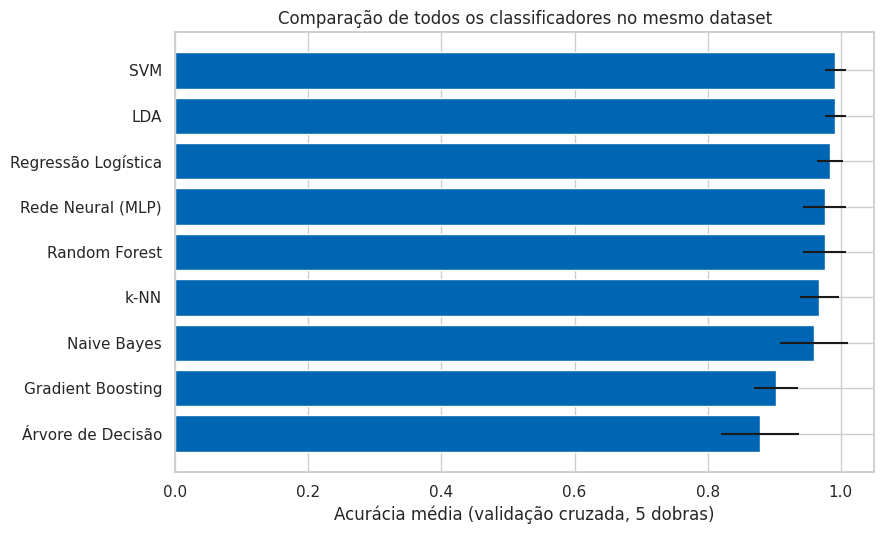

In [43]:
plt.figure(figsize=(9, 5.5))
plt.barh(tabela_classificadores.index[::-1], tabela_classificadores["acuracia_media"][::-1],
         xerr=tabela_classificadores["desvio"][::-1], color="#0066B3")
plt.xlabel("Acurácia média (validação cruzada, 5 dobras)")
plt.title("Comparação de todos os classificadores no mesmo dataset")
plt.xlim(0, 1.05)
plt.tight_layout()
plt.show()

> 📌 **Leitura:** repare no desvio-padrão de cada linha — diferenças menores que ele são **empate técnico**, não uma vitória real. Em um dataset pequeno, limpo e linearmente bem separável como o Wine, é comum que vários classificadores fiquem muito próximos: a Regressão Logística e a LDA costumam competir de igual para igual com os ensembles mais sofisticados, porque as classes já são quase linearmente separáveis nesta base.
>
> Esse é um resultado importante por si só: **o classificador mais complexo nem sempre é o melhor**. Vale sempre comparar antes de escolher.

# Módulo 6 — Hiperparâmetros, Grid Search e Random Search

> 🎯 **Objetivo:** entender a diferença entre um **parâmetro** (aprendido pelo `.fit()`) e um **hiperparâmetro** (escolhido por nós, antes do treino), e aprender duas formas sistemáticas de encontrar bons hiperparâmetros.

## 6.0 Parâmetro x hiperparâmetro

| | Parâmetro | Hiperparâmetro |
|---|---|---|
| Quem define | O algoritmo, durante o `.fit()` | A pessoa que programa, antes do `.fit()` |
| Exemplo | Os pesos $\beta$ da Regressão Logística | O `C` (força de regularização) da Regressão Logística |
| Onde aparece no código | `modelo.coef_`, depois do treino | Dentro dos parênteses ao instanciar: `LogisticRegression(C=1.0)` |

Até aqui, usamos os hiperparâmetros **padrão** do scikit-learn em todos os classificadores (`n_neighbors=5`, `max_depth=5`, e assim por diante). Funcionou razoavelmente bem — mas nada garante que os valores padrão sejam os melhores para o **nosso** dataset. Vamos buscar valores melhores de forma sistemática, em vez de tentar "no olho".

## 6.0.1 Grid Search: testar todas as combinações de uma grade

O `GridSearchCV` recebe uma **grade** de valores para cada hiperparâmetro e testa **todas as combinações possíveis**, usando validação cruzada em cada uma. Se `n_neighbors` tem 5 valores e `weights` tem 2, são $5 \times 2 = 10$ combinações, cada uma avaliada em 5 dobras — 50 treinos no total.

**Vantagem:** garante encontrar a melhor combinação **dentro da grade** que você definiu. **Desvantagem:** o número de combinações cresce rápido (é uma explosão combinatória) — inviável quando há muitos hiperparâmetros ou valores contínuos.

## 6.0.2 Random Search: sortear combinações

O `RandomizedSearchCV` não testa tudo. Em vez de uma grade fixa, você define **distribuições** de valores (por exemplo, "um número entre 0,01 e 100, numa escala logarítmica") e o algoritmo **sorteia** um número fixo de combinações (`n_iter`) para testar.

**Vantagem:** funciona bem mesmo com espaços grandes ou hiperparâmetros contínuos, com um custo computacional controlado por você. **Desvantagem:** não garante encontrar o ótimo — apenas uma boa região, com alta probabilidade.

| | Grid Search | Random Search |
|---|---|---|
| Como escolhe | Testa **todas** as combinações da grade | **Sorteia** `n_iter` combinações de distribuições |
| Quando usar | Poucos hiperparâmetros, valores discretos | Muitos hiperparâmetros, valores contínuos, espaço grande |
| Custo | Cresce multiplicando o nº de valores de cada hiperparâmetro | Controlado diretamente por `n_iter` |

Vamos aplicar um dos dois a cada um dos 9 classificadores — a escolha de qual usar já é, ela mesma, parte do aprendizado.

In [44]:
# Dicionário que vai guardar o melhor pipeline de CADA classificador, já ajustado e treinado
pipelines_ajustados = {}
# Dicionário que guarda os hiperparâmetros vencedores de cada busca (usado na Seção 6.11)
melhores_hiperparametros = {}
# Lista que vai acumular uma linha de resultado por classificador, para a tabela final da Seção 6.10
resultados_ajuste = []


def registrar_resultado(nome, buscador):
    """Guarda o pipeline vencedor, seus hiperparâmetros, e compara a acurácia antes/depois do ajuste."""
    pipelines_ajustados[nome] = buscador.best_estimator_
    melhores_hiperparametros[nome] = buscador.best_params_
    resultados_ajuste.append({
        "classificador": nome,
        "acuracia_padrao": tabela_classificadores.loc[nome, "acuracia_media"],
        "acuracia_ajustada": buscador.best_score_,
    })
    print(f"Melhores hiperparâmetros: {buscador.best_params_}")
    print(f"Acurácia com valores padrão: {tabela_classificadores.loc[nome, 'acuracia_media']:.3f}")
    print(f"Acurácia após o ajuste:     {buscador.best_score_:.3f}")

## 6.1 Regressão Logística

| Hiperparâmetro | O que controla |
|---|---|
| `C` | Inverso da força de regularização. Valores **menores** deixam o modelo mais simples (mais regularizado); valores **maiores** dão mais liberdade aos pesos |
| `penalty` | Tipo de penalização aplicada aos pesos (`l2` é o padrão) |

`C` é o hiperparâmetro que mais importa aqui, e assume poucos valores razoáveis — uma **grade pequena e discreta**. Usamos **Grid Search**.

In [45]:
grade_logistica = {"modelo__C": [0.01, 0.1, 1, 10, 100]}

busca_logistica = GridSearchCV(pipeline_logistica, grade_logistica, cv=validacao_cruzada,
                               scoring="accuracy", n_jobs=-1)
busca_logistica.fit(X_treino, y_treino)
registrar_resultado("Regressão Logística", busca_logistica)

Melhores hiperparâmetros: {'modelo__C': 10}
Acurácia com valores padrão: 0.984
Acurácia após o ajuste:     0.992


## 6.2 k-NN

| Hiperparâmetro | O que controla |
|---|---|
| `n_neighbors` | Quantos vizinhos consultar. Poucos = mais sensível a ruído; muitos = fronteira mais "borrada" |
| `weights` | `uniform`: todo vizinho vale o mesmo voto. `distance`: vizinhos mais próximos pesam mais |
| `p` | Ordem da distância de Minkowski: `1` = Manhattan, `2` = Euclidiana |

Três hiperparâmetros, todos discretos e com poucos valores plausíveis — a grade completa é pequena. **Grid Search**.

In [46]:
grade_knn = {"modelo__n_neighbors": [3, 5, 7, 9, 11, 15], "modelo__weights": ["uniform", "distance"],
            "modelo__p": [1, 2]}

busca_knn = GridSearchCV(pipeline_knn, grade_knn, cv=validacao_cruzada, scoring="accuracy", n_jobs=-1)
busca_knn.fit(X_treino, y_treino)
registrar_resultado("k-NN", busca_knn)

Melhores hiperparâmetros: {'modelo__n_neighbors': 5, 'modelo__p': 1, 'modelo__weights': 'uniform'}
Acurácia com valores padrão: 0.968
Acurácia após o ajuste:     0.992


## 6.3 SVM

| Hiperparâmetro | O que controla |
|---|---|
| `C` | Tolerância a erros de classificação: valores altos punem mais os erros (fronteira mais "apertada" aos dados) |
| `gamma` | Alcance de influência de cada ponto no kernel RBF: alto = fronteira recortada (risco de overfitting); baixo = fronteira suave |

`C` e `gamma` são **contínuos** — não existe uma lista natural e curta de valores para testar. Em vez de escolher pontos arbitrários numa grade, sorteamos valores de uma distribuição log-uniforme (mesma "densidade" de pontos em qualquer ordem de grandeza). **Random Search**.

In [47]:
distribuicoes_svm = {"modelo__C": loguniform(0.01, 100), "modelo__gamma": loguniform(1e-3, 1)}

busca_svm = RandomizedSearchCV(pipeline_svm, distribuicoes_svm, n_iter=20, cv=validacao_cruzada,
                               scoring="accuracy", random_state=SEMENTE, n_jobs=-1)
busca_svm.fit(X_treino, y_treino)
registrar_resultado("SVM", busca_svm)

Melhores hiperparâmetros: {'modelo__C': np.float64(8.471801418819979), 'modelo__gamma': np.float64(0.06251373574521749)}
Acurácia com valores padrão: 0.992
Acurácia após o ajuste:     0.992


## 6.4 Árvore de Decisão

| Hiperparâmetro | O que controla |
|---|---|
| `max_depth` | Quantas perguntas encadeadas a árvore pode fazer. Controla diretamente o overfitting |
| `min_samples_leaf` | Tamanho mínimo de um grupo final (folha). Folhas maiores = árvore mais conservadora |
| `criterion` | Medida de impureza usada para escolher os cortes (`gini` ou `entropy`) |

Três hiperparâmetros discretos, grade pequena o suficiente para testar por completo. **Grid Search**.

In [48]:
grade_arvore = {"modelo__max_depth": [2, 3, 4, 5, 6, None], "modelo__min_samples_leaf": [1, 2, 5, 10],
                "modelo__criterion": ["gini", "entropy"]}

busca_arvore = GridSearchCV(pipeline_arvore, grade_arvore, cv=validacao_cruzada, scoring="accuracy", n_jobs=-1)
busca_arvore.fit(X_treino, y_treino)
registrar_resultado("Árvore de Decisão", busca_arvore)

Melhores hiperparâmetros: {'modelo__criterion': 'gini', 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 1}
Acurácia com valores padrão: 0.878
Acurácia após o ajuste:     0.895


## 6.5 Random Forest

| Hiperparâmetro | O que controla |
|---|---|
| `n_estimators` | Quantas árvores compõem a floresta |
| `max_depth` | Profundidade máxima de cada árvore individual |
| `max_features` | Quantas variáveis cada corte pode considerar — controla a diversidade entre as árvores |

`n_estimators` combinado com os demais gera um espaço grande de combinações, e não há razão para testar **todos** os valores inteiros possíveis de número de árvores. **Random Search**.

In [49]:
distribuicoes_rf = {"modelo__n_estimators": randint(50, 300), "modelo__max_depth": [None, 5, 10, 15],
                    "modelo__max_features": ["sqrt", 0.5, None]}

busca_rf = RandomizedSearchCV(pipeline_random_forest, distribuicoes_rf, n_iter=15, cv=validacao_cruzada,
                              scoring="accuracy", random_state=SEMENTE, n_jobs=-1)
busca_rf.fit(X_treino, y_treino)
registrar_resultado("Random Forest", busca_rf)

Melhores hiperparâmetros: {'modelo__max_depth': 10, 'modelo__max_features': 'sqrt', 'modelo__n_estimators': 64}
Acurácia com valores padrão: 0.976
Acurácia após o ajuste:     0.976


## 6.6 Gradient Boosting

| Hiperparâmetro | O que controla |
|---|---|
| `n_estimators` | Quantas árvores sequenciais são treinadas |
| `learning_rate` | Peso da contribuição de cada árvore na soma final. Menor = mais conservador, exige mais árvores |
| `max_depth` | Profundidade de cada árvore — no boosting, costumam ser rasas |

`learning_rate` é contínuo e interage fortemente com `n_estimators`. Testar uma grade fixa desperdiçaria combinações pouco promissoras. **Random Search**.

In [50]:
distribuicoes_gb = {"modelo__n_estimators": randint(50, 200), "modelo__learning_rate": loguniform(0.01, 0.3),
                    "modelo__max_depth": randint(2, 5)}

busca_gb = RandomizedSearchCV(pipeline_gradient_boosting, distribuicoes_gb, n_iter=15, cv=validacao_cruzada,
                              scoring="accuracy", random_state=SEMENTE, n_jobs=-1)
busca_gb.fit(X_treino, y_treino)
registrar_resultado("Gradient Boosting", busca_gb)

Melhores hiperparâmetros: {'modelo__learning_rate': np.float64(0.1205712628744377), 'modelo__max_depth': 2, 'modelo__n_estimators': 70}
Acurácia com valores padrão: 0.903
Acurácia após o ajuste:     0.960


## 6.7 Naive Bayes

| Hiperparâmetro | O que controla |
|---|---|
| `var_smoothing` | Uma fração pequena somada à variância estimada de cada variável, para evitar problemas numéricos quando a variância é próxima de zero |

O Naive Bayes tem **quase nenhum** hiperparâmetro para ajustar — é parte do que o torna tão rápido e simples. Ainda assim, testamos alguns valores. **Grid Search** (a grade é pequena por natureza, não por escolha).

In [51]:
grade_naive_bayes = {"modelo__var_smoothing": [1e-11, 1e-9, 1e-7, 1e-5, 1e-3]}

busca_naive_bayes = GridSearchCV(pipeline_naive_bayes, grade_naive_bayes, cv=validacao_cruzada,
                                 scoring="accuracy", n_jobs=-1)
busca_naive_bayes.fit(X_treino, y_treino)
registrar_resultado("Naive Bayes", busca_naive_bayes)

Melhores hiperparâmetros: {'modelo__var_smoothing': 1e-11}
Acurácia com valores padrão: 0.960
Acurácia após o ajuste:     0.960


## 6.8 LDA

| Hiperparâmetro | O que controla |
|---|---|
| `solver` | Algoritmo usado para resolver o problema (`svd`, `lsqr` ou `eigen`) |
| `shrinkage` | Regularização da matriz de covariância — só se aplica quando `solver` é `lsqr` ou `eigen` |

Aqui aparece uma situação nova: `shrinkage` só faz sentido para **alguns** valores de `solver`. O `GridSearchCV` aceita uma **lista de grades** para esses casos, testando cada uma separadamente.

In [52]:
# Lista de duas grades: uma para "svd" (sem shrinkage) e outra para "lsqr"/"eigen" (com shrinkage)
grade_lda = [
    {"modelo__solver": ["svd"]},
    {"modelo__solver": ["lsqr", "eigen"], "modelo__shrinkage": ["auto", 0.1, 0.5]},
]

busca_lda = GridSearchCV(pipeline_lda, grade_lda, cv=validacao_cruzada, scoring="accuracy", n_jobs=-1)
busca_lda.fit(X_treino, y_treino)
registrar_resultado("LDA", busca_lda)

Melhores hiperparâmetros: {'modelo__solver': 'svd'}
Acurácia com valores padrão: 0.992
Acurácia após o ajuste:     0.992


## 6.9 Rede Neural (MLP)

| Hiperparâmetro | O que controla |
|---|---|
| `hidden_layer_sizes` | Quantas camadas ocultas e quantos neurônios em cada uma — controla a capacidade da rede |
| `alpha` | Força da regularização L2 sobre os pesos, para reduzir overfitting |
| `learning_rate_init` | Tamanho do passo inicial do otimizador durante o treino |

Três hiperparâmetros, dois deles contínuos, e cada treino é mais caro que os anteriores. **Random Search**, com um número de iterações moderado.

> ⚠️ **Aviso esperado:** dependendo da combinação sorteada de `learning_rate_init`, a rede pode não convergir dentro de `max_iter=1000` iterações, e o scikit-learn emite um `ConvergenceWarning`. Isso não é um erro — apenas informa que aquela combinação específica não teve tempo de estabilizar, o que já é, por si só, um sinal de que ela provavelmente não será a vencedora.

In [53]:
distribuicoes_mlp = {
    "modelo__hidden_layer_sizes": [(16,), (32,), (32, 16), (64, 32)],
    "modelo__alpha": loguniform(1e-5, 1e-1),
    "modelo__learning_rate_init": loguniform(1e-4, 1e-1),
}

busca_mlp = RandomizedSearchCV(pipeline_mlp, distribuicoes_mlp, n_iter=10, cv=validacao_cruzada,
                               scoring="accuracy", random_state=SEMENTE, n_jobs=-1)
busca_mlp.fit(X_treino, y_treino)
registrar_resultado("Rede Neural (MLP)", busca_mlp)

Melhores hiperparâmetros: {'modelo__alpha': np.float64(0.05678201970293124), 'modelo__hidden_layer_sizes': (32,), 'modelo__learning_rate_init': np.float64(0.0003511356313970409)}
Acurácia com valores padrão: 0.976
Acurácia após o ajuste:     0.992


## 6.10 O ganho do ajuste, classificador por classificador

Juntamos os 9 resultados em uma única tabela: acurácia com hiperparâmetros padrão versus acurácia depois do ajuste.

In [54]:
tabela_ajuste = pd.DataFrame(resultados_ajuste).set_index("classificador")
tabela_ajuste["ganho"] = tabela_ajuste["acuracia_ajustada"] - tabela_ajuste["acuracia_padrao"]
tabela_ajuste = tabela_ajuste.sort_values("acuracia_ajustada", ascending=False)
tabela_ajuste.round(4)

,acuracia_padrao,acuracia_ajustada,ganho
classificador,,,
Regressão Logística,0.9840,0.9920,0.0080
k-NN,0.9680,0.9920,0.0240
SVM,0.9920,0.9920,0.0000
LDA,0.9920,0.9920,0.0000
Rede Neural (MLP),0.9760,0.9920,0.0160
Random Forest,0.9760,0.9760,0.0000
Naive Bayes,0.9600,0.9600,0.0000
Gradient Boosting,0.9030,0.9597,0.0567
Árvore de Decisão,0.8783,0.8950,0.0167


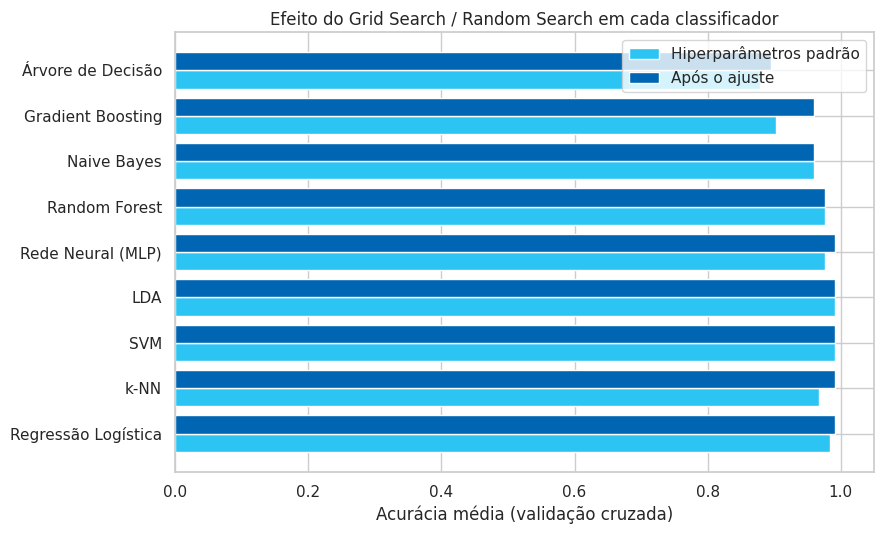

In [55]:
posicoes = np.arange(len(tabela_ajuste))
plt.figure(figsize=(9, 5.5))
plt.barh(posicoes - 0.2, tabela_ajuste["acuracia_padrao"], 0.4, label="Hiperparâmetros padrão", color="#2BC4F3")
plt.barh(posicoes + 0.2, tabela_ajuste["acuracia_ajustada"], 0.4, label="Após o ajuste", color="#0066B3")
plt.yticks(posicoes, tabela_ajuste.index)
plt.xlabel("Acurácia média (validação cruzada)")
plt.title("Efeito do Grid Search / Random Search em cada classificador")
plt.xlim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.show()

In [56]:
NOME_MODELO_FINAL = tabela_ajuste.index[0]
print(f"Modelo final, após o ajuste de hiperparâmetros: {NOME_MODELO_FINAL}")
print(f"Acurácia (validação cruzada): {tabela_ajuste.loc[NOME_MODELO_FINAL, 'acuracia_ajustada']:.3f}")

Modelo final, após o ajuste de hiperparâmetros: Regressão Logística
Acurácia (validação cruzada): 0.992


> 📌 **Leitura:** repare em **quais** classificadores ganharam mais com o ajuste. Modelos com hiperparâmetros que controlam diretamente a complexidade (Random Forest, Gradient Boosting, MLP, SVM) tendem a ganhar mais, porque o valor padrão raramente é o ideal para um dataset específico. Já o Naive Bayes e a LDA, que têm poucos hiperparâmetros — ou nenhum que mude muita coisa —, ganham pouco ou nada: não há muito o que ajustar.
>
> Esse é um resultado importante por si só: **nem todo classificador se beneficia igualmente de hiperparametrização.** Vale sempre medir o ganho antes de investir tempo de CPU em uma busca extensa.
>
> 🚩 **Sobre empates no topo:** é comum que vários classificadores cheguem à **mesma** acurácia depois do ajuste — neste dataset pequeno e bem separável, isso acontece com frequência. Quando há empate exato, `tabela_ajuste.index[0]` escolhe o primeiro da lista original (a ordem em que os classificadores foram ajustados nas Seções 6.1 a 6.9), não necessariamente "o melhor" de forma inequívoca. Em caso de empate, critérios de desempate razoáveis incluem simplicidade do modelo, tempo de inferência ou facilidade de explicar a decisão — não apenas a métrica.
>
> A partir daqui, `NOME_MODELO_FINAL` e `pipelines_ajustados` guardam o vencedor **já ajustado e treinado com todo o treino** — é esse pipeline que os Módulos 7 e 8 vão usar.

## 6.11 Do import ao pipeline treinado: o bloco completo

Depois de nove buscas, a Seção 6.10 apontou a vencedora: **Regressão Logística**, com `C=10` (Seção 6.1). Em vez de manter o código genérico para qualquer um dos 9 classificadores, vale reunir a receita final em um único bloco simples e direto — os imports, a leitura do dataset e o pipeline já treinado com a configuração vencedora.

> 💡 **Se, ao rodar o notebook de novo, outro classificador vencer** (pode acontecer com uma semente diferente, ou se algum dado mudar), esta célula não se atualiza sozinha — ela é a receita fixa para o resultado que obtivemos. Bastaria trocar o import e os hiperparâmetros abaixo pelos do novo vencedor.

In [57]:
# ============================================================
# Bloco completo: do import ao pipeline final treinado
# Classificador vencedor (Seção 6.10): Regressão Logística
# ============================================================

# 1) Imports
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# 2) Leitura do dataset
dados_finais = load_wine()
X_final = pd.DataFrame(dados_finais.data, columns=dados_finais.feature_names)
y_final = pd.Series(dados_finais.target)

# 3) Divisão treino/teste
X_treino_final, X_teste_final, y_treino_final, y_teste_final = train_test_split(
    X_final, y_final, test_size=0.30, stratify=y_final, random_state=SEMENTE)

# 4) Pipeline: padronização + Regressão Logística, com os hiperparâmetros vencedores do Módulo 6
pipeline_regressao_logistica = Pipeline([
    ("escalonador", StandardScaler()),   # padroniza cada variável para média 0 e desvio 1 (Módulo 3)
    ("modelo", LogisticRegression(
        C=10,                  # inverso da força de regularização - valor vencedor do Grid Search (Seção 6.1)
        max_iter=1000,         # iterações suficientes para o otimizador convergir
        random_state=SEMENTE,  # reprodutibilidade
    )),
])
pipeline_regressao_logistica.fit(X_treino_final, y_treino_final)

print(f"Acurácia no teste: {pipeline_regressao_logistica.score(X_teste_final, y_teste_final):.1%}")

Acurácia no teste: 98.1%


> 📌 **Por que isso importa:** este bloco não depende de nenhuma célula anterior do notebook — ele carrega o dataset, divide, monta o pipeline e treina, tudo a partir do zero. A lógica é a mesma que o Módulo 8 vai usar oficialmente (lá com o nome `pipeline_final`, guardado em `pipelines_ajustados[NOME_MODELO_FINAL]`) para salvar o modelo em disco e reutilizá-lo em dados novos.

## 6.12 O mesmo bloco, agora com redução de dimensionalidade (PCA)

O bloco da Seção 6.11 usa as 13 variáveis originais. Uma alternativa comum é **reduzir a dimensionalidade** antes do classificador, o que pode ajudar quando há muitas variáveis correlacionadas entre si — e a matriz de correlação do Módulo 1 já mostrou que algumas colunas do Wine caminham juntas.

Existem duas famílias de técnicas para isso, e vale saber a diferença:

| Técnica | O que faz | Interpretabilidade |
|---|---|---|
| **PCA** (Análise de Componentes Principais) | **Cria** novas variáveis (componentes), cada uma uma combinação linear de todas as originais, ordenadas pela variância que capturam | Perde-se: não dá mais para dizer "o álcool pesou X" — o que existe é "a componente 1 pesou X" |
| **Seleção de atributos** (ex.: `SelectKBest`) | **Escolhe** um subconjunto das variáveis originais, descartando as demais | Mantém-se: as variáveis que sobram continuam sendo `alcohol`, `magnesium`, etc. |

Vamos usar PCA aqui, por ser a mais comum dentro de um `Pipeline`. A única mudança em relação à Seção 6.11 é uma etapa nova, **entre** o scaler e o classificador — o PCA também é sensível à escala, por isso precisa vir depois do `StandardScaler` e antes do modelo.

In [58]:
# ============================================================
# Bloco completo: do import ao pipeline com PCA
# Mesma Regressão Logística da Seção 6.11, agora com redução de dimensionalidade
# ============================================================

# 1) Imports
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

# 2) Leitura do dataset
dados_pca = load_wine()
X_pca_dados = pd.DataFrame(dados_pca.data, columns=dados_pca.feature_names)
y_pca_dados = pd.Series(dados_pca.target)

# 3) Divisão treino/teste (mesma proporção e mesma semente da Seção 6.11, para comparar de forma justa)
X_treino_pca, X_teste_pca, y_treino_pca, y_teste_pca = train_test_split(
    X_pca_dados, y_pca_dados, test_size=0.30, stratify=y_pca_dados, random_state=SEMENTE)

# 4) Pipeline: padronização + PCA + Regressão Logística
pipeline_com_pca = Pipeline([
    ("escalonador", StandardScaler()),                      # o PCA também exige dados na mesma escala
    ("pca", PCA(n_components=0.95, random_state=SEMENTE)),  # mantém componentes suficientes p/ 95% da variância
    ("modelo", LogisticRegression(C=10, max_iter=1000, random_state=SEMENTE)),
])
pipeline_com_pca.fit(X_treino_pca, y_treino_pca)

componentes_mantidas = pipeline_com_pca.named_steps["pca"].n_components_
print(f"Variáveis originais:            {X_pca_dados.shape[1]}")
print(f"Componentes principais mantidas: {componentes_mantidas} (95% da variância original)")
print(f"\nAcurácia SEM PCA (Seção 6.11): {pipeline_regressao_logistica.score(X_teste_final, y_teste_final):.1%}")
print(f"Acurácia COM PCA ({X_pca_dados.shape[1]} -> {componentes_mantidas} variáveis): "
      f"{pipeline_com_pca.score(X_teste_pca, y_teste_pca):.1%}")

Variáveis originais:            13
Componentes principais mantidas: 10 (95% da variância original)

Acurácia SEM PCA (Seção 6.11): 98.1%
Acurácia COM PCA (13 -> 10 variáveis): 96.3%


> 📌 **Leitura:** com poucas variáveis, todas interpretáveis, e um modelo linear que já lida bem com colunas correlacionadas (a regularização do `C` ajuda nisso), o PCA raramente traz ganho de acurácia no Wine — o objetivo dele aqui não é o teste, é servir de referência pronta para usar. Ele se torna mais valioso quando há **dezenas ou centenas** de variáveis redundantes, quando o custo computacional do treino precisa cair, ou quando se quer visualizar os dados em 2 ou 3 dimensões. Se o objetivo fosse **manter a interpretabilidade** das variáveis originais em vez de reduzir redundância, a troca natural seria pela seleção de atributos (`SelectKBest`), no lugar do passo `"pca"` do pipeline.

---

# ⏸️ Fim da Aula 1

### O que vimos

- [ ] Como carregar e explorar um dataset de classificação.
- [ ] O padrão `Pipeline` do scikit-learn: scaler + modelo, treinado e avaliado sem vazamento.
- [ ] O efeito real de cada scaler, medido com dois classificadores diferentes.
- [ ] Treino/teste, treino/validação/teste e validação cruzada — e por que `StratifiedKFold` é o padrão em classificação.
- [ ] Por que o `Pipeline` é indispensável dentro da validação cruzada, não apenas uma conveniência de código.
- [ ] A teoria de treino e inferência de 9 classificadores do scikit-learn, e como instanciá-los.
- [ ] Como ajustar hiperparâmetros com Grid Search e Random Search, e quando usar cada um.

### O que vem na Aula 2

Com os dados, o pipeline e os classificadores já dominados, a Aula 2 é focada em **avaliação e uso prático**: as métricas de classificação explicadas com calma (o que são e como são calculadas), como salvar e reutilizar o modelo treinado, e os exercícios finais.

---

# ▶️ Aula 2 — Métricas, Persistência e Fechamento

**Retomada:** as células da Aula 1 precisam ser executadas novamente para reconstruir `X`, `y`, `X_treino`, `X_teste`, `validacao_cruzada`, `classificadores`, `pipeline_arvore`, `pipelines_ajustados`, `NOME_MODELO_FINAL` e as demais variáveis. No Colab, `Ambiente de execução > Executar tudo` resolve.

# Módulo 7 — Métricas de Classificação: o que são e como são calculadas

> 🎯 **Objetivo:** entender, com fórmula e cálculo manual, **como cada métrica de classificação é obtida** a partir da matriz de confusão — e não apenas chamar uma função do scikit-learn e confiar no número que ela devolve.

Para este bloco, vamos usar de propósito um modelo **imperfeito**: a Árvore de Decisão simples do Módulo 5 (`pipeline_arvore`), que erra algumas previsões no teste. Um modelo quase perfeito, como o vencedor do Módulo 6, tornaria os exemplos triviais (tudo daria 100%). Ao final, voltamos ao modelo final ajustado para a avaliação oficial.

## 7.1 A matriz de confusão: a base de tudo

Toda métrica de classificação que veremos neste módulo é calculada a partir de uma única tabela: a **matriz de confusão**. Ela cruza a classe **real** de cada amostra com a classe **prevista** pelo modelo.

Para explicar os quatro blocos fundamentais (Verdadeiro Positivo, Falso Positivo, Falso Negativo, Verdadeiro Negativo), vamos simplificar e olhar para **uma classe de cada vez** — por exemplo, "é `class_0`?" contra "não é `class_0`":

| | **Previsto: não é class_0** | **Previsto: é class_0** |
|---|---|---|
| **Real: não é class_0** | Verdadeiro Negativo (VN) | Falso Positivo (FP) |
| **Real: é class_0** | Falso Negativo (FN) | Verdadeiro Positivo (VP) |

- **VP (Verdadeiro Positivo):** o modelo disse "é esta classe", e acertou.
- **FP (Falso Positivo):** o modelo disse "é esta classe", mas era outra (um "alarme falso").
- **FN (Falso Negativo):** o modelo disse "não é esta classe", mas era ela (uma "perda").
- **VN (Verdadeiro Negativo):** o modelo disse "não é esta classe", e de fato não era.

Com 3 classes, o scikit-learn devolve uma matriz 3×3 — mas cada uma das 3 colunas/linhas pode ser reduzida a essa lógica de 4 blocos, olhando "esta classe" contra "todas as outras juntas" (a estratégia **um-contra-todos**, ou *one-vs-rest*).

In [59]:
# Modelo intencionalmente simples, para termos erros reais para analisar
previsoes_exemplo = pipeline_arvore.predict(X_teste)

matriz_exemplo = confusion_matrix(y_teste, previsoes_exemplo)
print("Matriz de confusão completa (linhas = classe real, colunas = classe prevista):\n")
print(pd.DataFrame(matriz_exemplo, index=nomes_classes, columns=nomes_classes))
print(f"\nTotal de amostras no teste: {len(y_teste)} | Acertos: {np.trace(matriz_exemplo)} | "
      f"Erros: {len(y_teste) - np.trace(matriz_exemplo)}")

Matriz de confusão completa (linhas = classe real, colunas = classe prevista):

         class_0  class_1  class_2
class_0       17        1        0
class_1        0       21        0
class_2        0        1       14

Total de amostras no teste: 54 | Acertos: 52 | Erros: 2


> 📌 **Como ler:** os números na **diagonal principal** são os acertos (a classe real bateu com a prevista). Qualquer número **fora** da diagonal é um erro — a linha diz qual era a classe real, a coluna diz em qual classe o modelo errou ao colocar a amostra.

Agora reduzimos a matriz 3×3 a um único bloco de 4 números, focando em uma classe:

In [60]:
CLASSE_EXEMPLO = 0   # vamos focar em "class_0" contra as demais

y_teste_binario = (y_teste == CLASSE_EXEMPLO).astype(int)
previsao_binaria = (previsoes_exemplo == CLASSE_EXEMPLO).astype(int)

# labels=[0, 1]: 0 = "não é a classe", 1 = "é a classe" - ravel() devolve nesta ordem: VN, FP, FN, VP
verdadeiro_negativo, falso_positivo, falso_negativo, verdadeiro_positivo = confusion_matrix(
    y_teste_binario, previsao_binaria, labels=[0, 1]).ravel()

print(f"Focando em '{nomes_classes[CLASSE_EXEMPLO]}' contra as demais classes:")
print(f"  Verdadeiro Positivo (VP) = {verdadeiro_positivo}  -> era {nomes_classes[CLASSE_EXEMPLO]}, o modelo acertou")
print(f"  Falso Positivo (FP)      = {falso_positivo}  -> NÃO era {nomes_classes[CLASSE_EXEMPLO]}, o modelo disse que era")
print(f"  Falso Negativo (FN)      = {falso_negativo}  -> ERA {nomes_classes[CLASSE_EXEMPLO]}, o modelo disse que não")
print(f"  Verdadeiro Negativo (VN) = {verdadeiro_negativo}  -> não era, e o modelo disse que não")

Focando em 'class_0' contra as demais classes:
  Verdadeiro Positivo (VP) = 17  -> era class_0, o modelo acertou
  Falso Positivo (FP)      = 0  -> NÃO era class_0, o modelo disse que era
  Falso Negativo (FN)      = 1  -> ERA class_0, o modelo disse que não
  Verdadeiro Negativo (VN) = 36  -> não era, e o modelo disse que não


## 7.2 Acurácia

A métrica mais intuitiva: entre **todas** as previsões, qual fração estava certa?

$$\text{Acurácia} = \frac{VP + VN}{VP + VN + FP + FN}$$

Repare que ela olha para os 4 blocos ao mesmo tempo — é por isso que, em uma classe rara, a acurácia pode ficar "artificialmente" alta: quando a maioria das amostras é VN (a classe realmente não era aquela, e o modelo disse corretamente que não era), até um modelo ruim acerta muito.

In [61]:
acuracia_manual = (verdadeiro_positivo + verdadeiro_negativo) / len(y_teste_binario)
acuracia_sklearn = accuracy_score(y_teste_binario, previsao_binaria)

print(f"Cálculo manual: ({verdadeiro_positivo} + {verdadeiro_negativo}) / {len(y_teste_binario)} = {acuracia_manual:.4f}")
print(f"accuracy_score do scikit-learn:                     {acuracia_sklearn:.4f}")

Cálculo manual: (17 + 36) / 54 = 0.9815
accuracy_score do scikit-learn:                     0.9815


## 7.3 Precisão e Recall

Estas duas métricas olham para lados diferentes do erro, e é raro conseguir maximizar as duas ao mesmo tempo.

$$\text{Precisão} = \frac{VP}{VP + FP} \qquad\qquad \text{Recall} = \frac{VP}{VP + FN}$$

- **Precisão** responde: *"das vezes que o modelo disse que era esta classe, quantas realmente eram?"* — pune os **Falsos Positivos**.
- **Recall** responde: *"das amostras que realmente eram esta classe, quantas o modelo encontrou?"* — pune os **Falsos Negativos**.

**Por que isso importa na prática:** em um exame médico, um Falso Negativo (dizer que a pessoa está saudável quando não está) costuma ser muito mais grave que um Falso Positivo — então recall importa mais. Já em um filtro de spam, um Falso Positivo (jogar um e-mail importante para o lixo) costuma incomodar mais que deixar passar um spam — então precisão importa mais. A métrica certa depende do **custo de cada tipo de erro** no seu problema, não existe uma resposta universal.

In [62]:
precisao_manual = verdadeiro_positivo / (verdadeiro_positivo + falso_positivo)
recall_manual = verdadeiro_positivo / (verdadeiro_positivo + falso_negativo)

print(f"Precisão = VP/(VP+FP) = {verdadeiro_positivo}/({verdadeiro_positivo}+{falso_positivo}) = {precisao_manual:.4f}")
print(f"Recall   = VP/(VP+FN) = {verdadeiro_positivo}/({verdadeiro_positivo}+{falso_negativo}) = {recall_manual:.4f}")

print("\nConferindo com o scikit-learn (usando apenas a classe de interesse):")
print(f"  precision_score: {precision_score(y_teste_binario, previsao_binaria):.4f}")
print(f"  recall_score:    {recall_score(y_teste_binario, previsao_binaria):.4f}")

Precisão = VP/(VP+FP) = 17/(17+0) = 1.0000
Recall   = VP/(VP+FN) = 17/(17+1) = 0.9444

Conferindo com o scikit-learn (usando apenas a classe de interesse):
  precision_score: 1.0000
  recall_score:    0.9444


## 7.4 F1-Score

Quando não há um motivo claro para priorizar precisão ou recall, o F1-Score resume as duas em um único número — a **média harmônica** entre elas:

$$F_1 = 2 \cdot \frac{\text{Precisão} \times \text{Recall}}{\text{Precisão} + \text{Recall}}$$

> 💡 **Por que média harmônica, e não a média simples?** A média harmônica só fica alta quando **as duas** métricas são altas. Se a precisão for 1,0 e o recall for 0,1, a média simples seria 0,55 — um número enganosamente bom. A média harmônica desse mesmo par é 0,18, refletindo melhor que o modelo está falhando muito no recall. Ela **pune o desequilíbrio** entre as duas métricas.

In [63]:
f1_manual = 2 * (precisao_manual * recall_manual) / (precisao_manual + recall_manual)
print(f"F1 = 2 x ({precisao_manual:.4f} x {recall_manual:.4f}) / ({precisao_manual:.4f} + {recall_manual:.4f}) = {f1_manual:.4f}")
print(f"f1_score do scikit-learn:                                                        {f1_score(y_teste_binario, previsao_binaria):.4f}")

F1 = 2 x (1.0000 x 0.9444) / (1.0000 + 0.9444) = 0.9714
f1_score do scikit-learn:                                                        0.9714


## 7.5 De volta às 3 classes: médias macro, weighted e micro

As fórmulas acima valem para **uma** classe contra o resto. Com 3 classes, calculamos precisão (ou recall, ou F1) **para cada uma** e depois combinamos em um único número, de três formas possíveis:

| Média | Como calcula | Quando usar |
|---|---|---|
| **macro** | Média simples das métricas de cada classe, com **peso igual** | Quando todas as classes importam igualmente, mesmo as pequenas |
| **weighted** | Média ponderada pelo **suporte** (nº de amostras reais) de cada classe | Quando classes maiores devem pesar mais no resultado final |
| **micro** | Soma os VP, FP e FN de **todas** as classes primeiro, e só então aplica a fórmula | Dá mais peso, na prática, às classes com mais amostras — e em classificação multiclasse de rótulo único, a precisão micro é sempre igual à acurácia |

In [64]:
precisao_por_classe = precision_score(y_teste, previsoes_exemplo, average=None)
suporte_por_classe = pd.Series(y_teste).value_counts().sort_index().values

print("Precisão de cada classe:", dict(zip(nomes_classes, [round(float(v), 4) for v in precisao_por_classe])))
print("Suporte (amostras reais) de cada classe:", dict(zip(nomes_classes, [int(v) for v in suporte_por_classe])))

# macro: média simples
precisao_macro_manual = precisao_por_classe.mean()
# weighted: média ponderada pelo suporte de cada classe
precisao_weighted_manual = np.average(precisao_por_classe, weights=suporte_por_classe)

print(f"\nMacro    (média simples):            {precisao_macro_manual:.4f}  "
      f"| scikit-learn: {precision_score(y_teste, previsoes_exemplo, average='macro'):.4f}")
print(f"Weighted (ponderada pelo suporte):    {precisao_weighted_manual:.4f}  "
      f"| scikit-learn: {precision_score(y_teste, previsoes_exemplo, average='weighted'):.4f}")
print(f"Micro    (soma tudo antes de dividir): {'—':>6}  "
      f"| scikit-learn: {precision_score(y_teste, previsoes_exemplo, average='micro'):.4f}  "
      f"(compare com a acurácia: {accuracy_score(y_teste, previsoes_exemplo):.4f})")

Precisão de cada classe: {'class_0': 1.0, 'class_1': 0.913, 'class_2': 1.0}
Suporte (amostras reais) de cada classe: {'class_0': 18, 'class_1': 21, 'class_2': 15}

Macro    (média simples):            0.9710  | scikit-learn: 0.9710
Weighted (ponderada pelo suporte):    0.9662  | scikit-learn: 0.9662
Micro    (soma tudo antes de dividir):      —  | scikit-learn: 0.9630  (compare com a acurácia: 0.9630)


> 📌 **Leitura:** se as três médias derem valores parecidos, as classes têm desempenho parecido entre si. Se `weighted` for bem diferente de `macro`, é sinal de que alguma classe **pequena** está com desempenho muito diferente das demais — e a média `macro` é a que revela isso, porque não deixa o tamanho da classe "esconder" o problema.

## 7.6 Aplicando ao modelo final

Com a teoria estabelecida, voltamos ao classificador escolhido no Módulo 6 (já ajustado) e olhamos seu desempenho no conjunto de teste. O `classification_report` do scikit-learn calcula, de uma vez, tudo o que acabamos de fazer manualmente: precisão, recall e F1 por classe, além das médias macro e weighted.

In [65]:
NOME_MELHOR_MODELO = NOME_MODELO_FINAL
melhor_pipeline = pipelines_ajustados[NOME_MODELO_FINAL]   # já treinado com todo o X_treino
previsoes_teste = melhor_pipeline.predict(X_teste)

print(f"Melhor classificador (após ajuste de hiperparâmetros): {NOME_MELHOR_MODELO}\n")
print(classification_report(y_teste, previsoes_teste, target_names=nomes_classes, digits=3))

Melhor classificador (após ajuste de hiperparâmetros): Regressão Logística

              precision    recall  f1-score   support

     class_0      0.947     1.000     0.973        18
     class_1      1.000     0.952     0.976        21
     class_2      1.000     1.000     1.000        15

    accuracy                          0.981        54
   macro avg      0.982     0.984     0.983        54
weighted avg      0.982     0.981     0.982        54



> 📌 **Leitura do relatório:** `support` é o número de amostras reais de cada classe no teste — os mesmos valores que calculamos à mão na Seção 7.5. Se alguma classe tiver precisão ou recall visivelmente mais baixos que as outras, é sinal de que o modelo tem mais dificuldade em distingui-la.

## 7.7 Matriz de confusão gráfica

A mesma matriz da Seção 7.1, agora para o modelo final, em forma de mapa de calor.

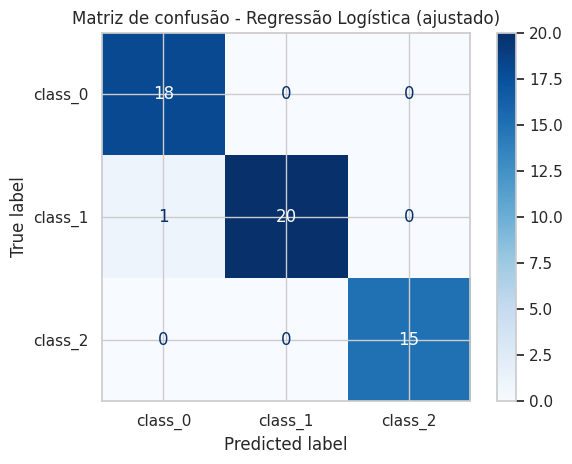

In [66]:
ConfusionMatrixDisplay.from_predictions(y_teste, previsoes_teste, display_labels=nomes_classes, cmap="Blues")
plt.title(f"Matriz de confusão - {NOME_MELHOR_MODELO} (ajustado)")
plt.tight_layout()
plt.show()

## 7.8 Curva ROC e AUC

A curva ROC (*Receiver Operating Characteristic*) mostra como **duas taxas mudam juntas** conforme variamos o limiar de decisão do modelo (o ponto de corte da probabilidade a partir do qual dizemos "é esta classe"):

$$\text{TPR (recall)} = \frac{VP}{VP + FN} \qquad\qquad \text{FPR} = \frac{FP}{FP + VN}$$

- **TPR** (Taxa de Verdadeiros Positivos) é exatamente o **recall** que já vimos.
- **FPR** (Taxa de Falsos Positivos) mede a fração dos negativos reais que foram classificados por engano como positivos.

Cada ponto da curva corresponde a **um limiar diferente**. Um limiar bem baixo classifica quase tudo como positivo (TPR alto, mas FPR também alto); um limiar bem alto faz o oposto. A **AUC** (Área sob a Curva) resume a curva inteira em um número entre 0 e 1: é a probabilidade de que, sorteando uma amostra positiva e uma negativa ao acaso, o modelo dê uma probabilidade maior para a positiva. Um classificador aleatório tem AUC = 0,5 (a diagonal do gráfico); um classificador perfeito tem AUC = 1,0.

Com 3 classes, plotamos uma curva **por classe**, sempre na estratégia um-contra-todos.

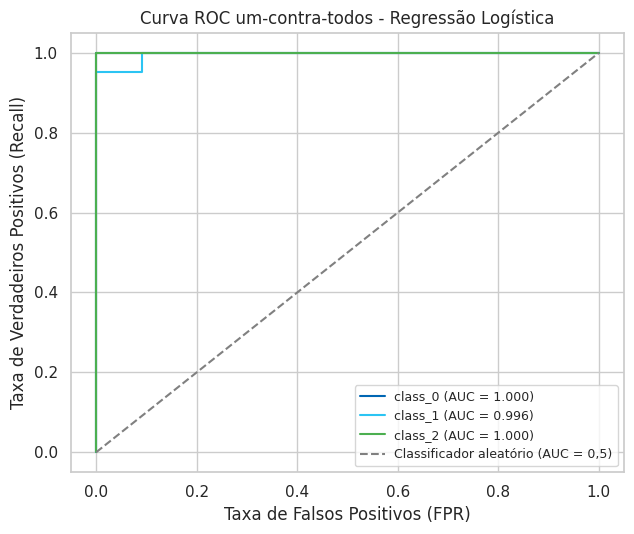

ROC-AUC (média macro das 3 curvas): 0.999


In [67]:
probabilidades_teste = melhor_pipeline.predict_proba(X_teste)

plt.figure(figsize=(6.5, 5.5))
cores_classes = ["#0066B3", "#2BC4F3", "#4CAF50"]
for classe, cor in zip(range(len(nomes_classes)), cores_classes):
    fpr, tpr, limiares = roc_curve((y_teste == classe).astype(int), probabilidades_teste[:, classe])
    auc_classe = roc_auc_score((y_teste == classe).astype(int), probabilidades_teste[:, classe])
    plt.plot(fpr, tpr, color=cor, label=f"{nomes_classes[classe]} (AUC = {auc_classe:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Classificador aleatório (AUC = 0,5)")
plt.xlabel("Taxa de Falsos Positivos (FPR)")
plt.ylabel("Taxa de Verdadeiros Positivos (Recall)")
plt.title(f"Curva ROC um-contra-todos - {NOME_MELHOR_MODELO}")
plt.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

roc_auc_multiclasse = roc_auc_score(y_teste, probabilidades_teste, multi_class="ovr", average="macro")
print(f"ROC-AUC (média macro das 3 curvas): {roc_auc_multiclasse:.3f}")

> 📌 **Um ROC-AUC de 1,000 (ou muito próximo), e curvas quase coladas no canto superior esquerdo, são esperados aqui, não um erro.** As variáveis químicas do Wine separam as 3 cultivares quase perfeitamente. Em datasets reais, mais ruidosos, as curvas ficam mais afastadas desse canto ideal, e é aí que comparar a AUC entre classificadores se torna mais informativo.

## 7.9 Todas as métricas, todos os classificadores

Fechamos com uma única tabela: os 9 classificadores **com hiperparâmetros padrão** (os mesmos do Módulo 5, antes do ajuste), avaliados por validação cruzada, em quatro métricas ao mesmo tempo. É um retrato rápido e multi-métrica do ranking inicial — o Módulo 6 já mostrou o ganho de cada um depois do ajuste, focado na acurácia.

In [68]:
metricas_multiplas = {
    "acuracia": "accuracy",
    "precisao_macro": "precision_macro",
    "recall_macro": "recall_macro",
    "f1_macro": "f1_macro",
}

linhas_finais = []
for nome, modelo in classificadores.items():
    pipeline = Pipeline([("escalonador", StandardScaler()), ("modelo", modelo)])
    resultado = cross_validate(pipeline, X_treino, y_treino, cv=validacao_cruzada, scoring=metricas_multiplas)
    linha = {"classificador": nome}
    linha.update({metrica: resultado[f"test_{metrica}"].mean() for metrica in metricas_multiplas})
    linhas_finais.append(linha)

tabela_final = pd.DataFrame(linhas_finais).set_index("classificador").sort_values("f1_macro", ascending=False)
tabela_final.round(3)

,acuracia,precisao_macro,recall_macro,f1_macro
classificador,,,,
SVM,0.992,0.992,0.993,0.992
LDA,0.992,0.992,0.993,0.992
Regressão Logística,0.984,0.982,0.987,0.983
Random Forest,0.976,0.975,0.980,0.976
Rede Neural (MLP),0.976,0.975,0.978,0.976
k-NN,0.968,0.971,0.973,0.970
Naive Bayes,0.960,0.961,0.964,0.960
Gradient Boosting,0.903,0.914,0.898,0.896
Árvore de Decisão,0.878,0.894,0.874,0.877


> 📌 **Neste dataset**, as quatro métricas costumam concordar bastante entre si — sinal de que as classes são relativamente fáceis de separar e não há uma classe "problemática" sendo escondida pela acurácia. Em datasets desbalanceados ou com classes mais parecidas entre si, é comum ver essas métricas divergirem, e é nesse cenário que escolher a métrica certa faz toda a diferença.

# Módulo 8 — Salvando e Reutilizando o Modelo

> 🎯 **Objetivo:** treinar o modelo **uma vez**, salvá-lo em disco, e usá-lo depois para prever dados novos — sem precisar retreinar nada.
>
> 📌 **Por que importa:** em qualquer aplicação real, o treino acontece uma vez (ou periodicamente), mas a **inferência** acontece o tempo todo, muitas vezes em outro programa, outro dia, outro computador. É preciso persistir o que foi aprendido.

## 8.1 O modelo final

O Módulo 6 já escolheu o classificador de melhor desempenho **após o ajuste de hiperparâmetros** (`NOME_MODELO_FINAL`) e o treinou com todo o conjunto de treino, dentro de `pipelines_ajustados`. Vamos usar exatamente esse pipeline — o mesmo que avaliamos no Módulo 7.

In [69]:
print(f"Modelo escolhido: {NOME_MODELO_FINAL}")

# Reaproveita o pipeline já ajustado e treinado no Módulo 6 - nenhum novo treino acontece aqui
pipeline_final = pipelines_ajustados[NOME_MODELO_FINAL]

print(f"Acurácia no conjunto de teste: {pipeline_final.score(X_teste, y_teste):.1%}")

Modelo escolhido: Regressão Logística
Acurácia no conjunto de teste: 98.1%


## 8.2 Salvando o pipeline completo (o jeito recomendado)

Um erro comum é salvar **só o modelo** e esquecer o scaler. Se isso acontecer, dados novos chegariam sem padronização, e o modelo — treinado com dados padronizados — receberia números em uma escala completamente diferente da que aprendeu, gerando previsões sem sentido.

A solução é salvar o **pipeline inteiro** (scaler + modelo, como um único objeto) usando a biblioteca `joblib`. Assim, carregar o pipeline já traz as duas etapas, sempre na ordem certa.

In [70]:
import joblib

# joblib.dump grava o objeto Python inteiro em um arquivo binário
joblib.dump(pipeline_final, "pipeline_vinho.pkl")
print("Pipeline (scaler + modelo) salvo em 'pipeline_vinho.pkl'")

Pipeline (scaler + modelo) salvo em 'pipeline_vinho.pkl'


## 8.3 Carregando o pipeline e prevendo dados novos

Simulamos o que aconteceria em **outro programa**, **outro dia**: carregamos o arquivo do zero e usamos para classificar um vinho que nunca foi visto por nenhuma etapa do treino.

In [71]:
# Carrega o pipeline salvo, como se fosse a primeira vez que este código roda
pipeline_carregado = joblib.load("pipeline_vinho.pkl")

# Um vinho novo, com valores plausíveis para as 13 variáveis (na mesma ordem das colunas originais)
vinho_desconhecido = pd.DataFrame([{
    "alcohol": 13.2, "malic_acid": 1.8, "ash": 2.3, "alcalinity_of_ash": 17.0, "magnesium": 105.0,
    "total_phenols": 2.6, "flavanoids": 2.5, "nonflavanoid_phenols": 0.3, "proanthocyanins": 1.6,
    "color_intensity": 4.5, "hue": 1.0, "od280/od315_of_diluted_wines": 3.0, "proline": 900.0,
}])

previsao = pipeline_carregado.predict(vinho_desconhecido)
probabilidade = pipeline_carregado.predict_proba(vinho_desconhecido)

print(f"Classe prevista: {nomes_classes[previsao[0]]}")
print("Probabilidade por classe:", probabilidades_legiveis(probabilidade[0]))

Classe prevista: class_0
Probabilidade por classe: {'class_0': 0.978, 'class_1': 0.022, 'class_2': 0.0}


> 📌 **Reparem no que acabou de acontecer.** O `pipeline_carregado` aplicou automaticamente o `StandardScaler` (com a média e o desvio-padrão aprendidos no treino original) **antes** de chamar o modelo. Não escrevemos nenhum código de padronização aqui — o pipeline cuidou disso sozinho, exatamente como fez durante o treino. É esse o valor de salvar o pipeline inteiro em vez de só o modelo.

## 8.4 Por dentro do pipeline: salvando scaler e modelo separadamente

Para entender **por que** isso funciona, vale ver a versão manual — sem o `Pipeline` — salvando cada peça em um arquivo próprio. Não é a forma recomendada (é mais fácil errar a ordem ou esquecer uma etapa), mas mostra o mecanismo por baixo do capô.

In [72]:
# Treinando scaler e modelo em separado, para fins didáticos
scaler_separado = StandardScaler().fit(X_treino)
X_treino_padronizado = scaler_separado.transform(X_treino)

# Clona o mesmo modelo (já com os hiperparâmetros ajustados no Módulo 6) e treina isoladamente
modelo_base_ajustado = pipeline_final.named_steps["modelo"]
modelo_separado = modelo_base_ajustado.__class__(**modelo_base_ajustado.get_params())
modelo_separado.fit(X_treino_padronizado, y_treino)

# Salva os DOIS arquivos separadamente
joblib.dump(scaler_separado, "scaler_vinho.pkl")
joblib.dump(modelo_separado, "modelo_vinho.pkl")
print("Scaler salvo em 'scaler_vinho.pkl' e modelo salvo em 'modelo_vinho.pkl'.")

Scaler salvo em 'scaler_vinho.pkl' e modelo salvo em 'modelo_vinho.pkl'.


In [73]:
# Usando os dois arquivos separados: é preciso aplicar o scaler ANTES de chamar o modelo,
# manualmente e na ordem certa - o que o Pipeline faz por nós automaticamente.
scaler_carregado = joblib.load("scaler_vinho.pkl")
modelo_carregado = joblib.load("modelo_vinho.pkl")

vinho_desconhecido_padronizado = scaler_carregado.transform(vinho_desconhecido)
previsao_manual = modelo_carregado.predict(vinho_desconhecido_padronizado)

print(f"Classe prevista (caminho manual): {nomes_classes[previsao_manual[0]]}")
print("Mesma previsão do pipeline?", previsao_manual[0] == previsao[0])

Classe prevista (caminho manual): class_0
Mesma previsão do pipeline? True


> 🚩 **Armadilha comum:** se alguém esquecer a linha `scaler_carregado.transform(...)` e chamar `modelo_carregado.predict(vinho_desconhecido)` diretamente com os dados **crus**, o código roda sem erro — mas a previsão pode estar completamente errada, porque o modelo foi treinado com números padronizados e está recebendo números em outra escala. O `Pipeline` da Seção 8.2 e 8.3 elimina esse risco por completo, e é por isso que é a forma recomendada.

## Resumo do módulo

| Abordagem | Como salvar | Como carregar | Risco |
|---|---|---|---|
| **Pipeline completo** (recomendado) | `joblib.dump(pipeline, "arquivo.pkl")` | `joblib.load(...)`, depois `.predict(dados_crus)` | Nenhum — a ordem das etapas é garantida |
| Scaler e modelo separados | Um `joblib.dump` para cada objeto | Carregar os dois e aplicar `scaler.transform()` **antes** de `modelo.predict()` | Esquecer o `transform`, ou aplicá-lo na ordem errada |

# Módulo 9 — Fechamento

### Checklist do que praticamos

- [ ] Construímos um pipeline completo: dados → split → padronização → modelo → métricas.
- [ ] Medimos o efeito real de 4 scalers em 2 classificadores diferentes.
- [ ] Comparamos split único e validação cruzada, e vimos a variação entre sementes.
- [ ] Conhecemos e instanciamos 9 classificadores do scikit-learn.
- [ ] Comparamos todos os classificadores no mesmo protocolo, com 4 métricas diferentes.
- [ ] Ajustamos os hiperparâmetros de cada classificador com Grid Search ou Random Search.
- [ ] Salvamos o pipeline completo (scaler + modelo) e o usamos para prever um dado novo, sem retreinar nada.

### Resumo mental

| Pergunta | Resposta prática |
|---|---|
| Preciso escalar meus dados? | Sim, sempre — nunca prejudica, e é essencial para modelos de distância e margem |
| Split único ou validação cruzada? | Validação cruzada para comparar; split único (uma vez) para a avaliação final |
| Qual classificador escolher? | Comece simples (Regressão Logística), compare com 2-3 alternativas, e leve o desvio-padrão em conta |
| Grid ou Random Search? | Grid para poucos hiperparâmetros discretos; Random para espaços grandes ou contínuos |
| Qual métrica usar? | Acurácia só em classes balanceadas; senão, precisão/recall/F1 pela classe que mais importa |

## Exercícios

### Exercício 1 — Trocando o scaler do melhor modelo

Refaça a validação cruzada do `NOME_MELHOR_MODELO` trocando `StandardScaler` por `MinMaxScaler` e depois por `RobustScaler`. O resultado muda? Isso é esperado, dado o que vimos no Módulo 3?

In [74]:
# TODO: monte um pipeline com MinMaxScaler e o classificador guardado em classificadores[NOME_MELHOR_MODELO],
# avalie com cross_val_score (mesma validacao_cruzada, scoring="accuracy") e imprima o resultado.

In [75]:
#@title 🔒 Gabarito — Exercício 1 { display-mode: "form" }
for nome_scaler, scaler in {"MinMaxScaler": MinMaxScaler(), "RobustScaler": RobustScaler()}.items():
    pipeline_teste = Pipeline([("escalonador", scaler), ("modelo", classificadores[NOME_MELHOR_MODELO])])
    notas = cross_val_score(pipeline_teste, X_treino, y_treino, cv=validacao_cruzada, scoring="accuracy")
    print(f"{NOME_MELHOR_MODELO} com {nome_scaler}: {notas.mean():.3f}")

# Se o melhor modelo for baseado em árvores (Random Forest, Gradient Boosting, Árvore de Decisão),
# o resultado deve mudar muito pouco - eles são invariantes a essas transformações (Módulo 3).
# Se for um modelo linear ou de distância, algum efeito pode aparecer, ainda que pequeno.

Regressão Logística com MinMaxScaler: 0.976
Regressão Logística com RobustScaler: 0.984


### Exercício 2 — Acrescentando um novo classificador

O scikit-learn tem muitos outros classificadores além dos 9 apresentados. Acrescente o `AdaBoostClassifier` (`from sklearn.ensemble import AdaBoostClassifier`) ao dicionário `classificadores`, refaça a comparação da Seção 5.11 e veja em que posição ele fica no ranking.

In [76]:
# TODO: importe o AdaBoostClassifier, instancie-o, acrescente ao dicionário `classificadores`
# e repita o laço de cross_val_score da Seção 5.11 para ver onde ele se posiciona.

In [77]:
#@title 🔒 Gabarito — Exercício 2 { display-mode: "form" }
from sklearn.ensemble import AdaBoostClassifier

classificadores["AdaBoost"] = AdaBoostClassifier(n_estimators=100, random_state=SEMENTE)

pipeline_ada = Pipeline([("escalonador", StandardScaler()), ("modelo", classificadores["AdaBoost"])])
notas_ada = cross_val_score(pipeline_ada, X_treino, y_treino, cv=validacao_cruzada, scoring="accuracy")
print(f"AdaBoost: {notas_ada.mean():.3f} (comparar com a tabela da Seção 5.11)")

AdaBoost: 0.952 (comparar com a tabela da Seção 5.11)


### Para ir além

1. No Módulo 8, salve o **segundo melhor** classificador da Seção 6.10 em um novo arquivo `.pkl` e compare as previsões dos dois modelos para o mesmo `vinho_desconhecido`.
2. Repita a comparação de scalers (Módulo 3) usando a **SVM** em vez do k-NN.
3. No Módulo 7, troque a média `macro` por `weighted` no `classification_report` (`average="weighted"` nas funções de métrica) e compare os números — a diferença aparece quando as classes têm tamanhos diferentes.
4. Refine o Grid Search do k-NN (Seção 6.2) incluindo o hiperparâmetro `p` (ordem da distância de Minkowski: 1 = Manhattan, 2 = Euclidiana) e veja se o resultado melhora.

### Referência

Dataset: *Wine recognition data*, UCI Machine Learning Repository, embutido no scikit-learn via `sklearn.datasets.load_wine`.